# Agri Predictive Analytics Model: district-level crop-yield forecasting
**Nagpur-region agri-tech start-up (fictional) | Vidarbha districts: Nagpur, Wardha, Amravati, Yavatmal, Chandrapur, Bhandara**

> **Data disclosure.** The brief describes a fictional company and no real dataset was supplied. All data in this notebook is
> **synthetic**, produced by `gen_data.py` (fixed seed `20261119`, run once, no seed-shopping). It reproduces the data problems named in the
> brief (mixed ₹/quintal and ₹/kg prices in one column, missing monsoon rainfall, yields in wrong units) and keeps a separate *ground-truth* file that is used
> **only to audit the cleaning code**, never as model input. Every number below describes this simulated world, not real Vidarbha agriculture.

**Business question.** Which district-crop pairs will under-deliver *this season*, early enough (≈6-8 weeks before harvest) to change procurement plans?

**Forecast origin (what "early" means here).** Kharif crops (cotton, soybean, tur, rice): forecast at **30 Sep**, using rain Jun-Sep. Rabi crops (wheat, gram): forecast at **31 Jan**, using rain Jun-Jan.
Anything observed after that date is *post-cutoff* and treated as leakage.

**Contents:** 1 Load & profile → 2 Cleaning (with audit) → 3 EDA → 4 Feature engineering → 5 Leakage audit → 6 Time-aware split → 7 Models & CV → 8 Tuning → 9 Evaluation → 10 Explainability → 11 One wrong prediction → 12 Fairness & stability → 13 Procurement actions → 14 Save artefacts

In [1]:
import os, json, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
QUICK = os.environ.get("QUICK") == "1"          # QUICK=1 only used while debugging (smaller models)
DATA, FIG, OUTD = "data", "figures", "outputs"
for d in (FIG, OUTD): os.makedirs(d, exist_ok=True)
RNG = 42
METRICS = {}                                     # everything quoted in the report/deck is written here
def savefig(name): plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
DIST = ["Nagpur", "Wardha", "Amravati", "Yavatmal", "Chandrapur", "Bhandara"]
CROPS = ["cotton", "soybean", "tur", "rice", "wheat", "gram"]
SEASON = dict(cotton="kharif", soybean="kharif", tur="kharif", rice="kharif", wheat="rabi", gram="rabi")
# Agronomic reference tables (domain assumptions, not learned from data)
WATER_REQ = dict(cotton=750, soybean=760, tur=720, rice=950, wheat=880, gram=880)     # mm to forecast cutoff
SOW_OPT = dict(cotton=25, soybean=25, tur=26, rice=27, wheat=45, gram=43)             # optimum sowing week
PH_OPT = dict(cotton=7.5, soybean=6.8, tur=7.0, rice=6.5, wheat=7.0, gram=7.2)
BASE_N = dict(cotton=100, soybean=25, tur=20, rice=100, wheat=110, gram=20)           # reference N kg/ha

## 1. Load and profile the raw tables

In [2]:
if not os.path.exists(f"{DATA}/yields.csv"):                 # regenerate the synthetic data if it is not on disk
    import subprocess, sys; subprocess.run([sys.executable, "gen_data.py"], check=True)
raw = {k: pd.read_csv(f"{DATA}/{k}.csv") for k in ["yields", "rainfall", "soil", "mandi", "area_stats", "cost_index"]}
prof = pd.DataFrame({k: {"rows": len(v), "cols": v.shape[1], "missing_cells_%": round(100 * v.isna().mean().mean(), 2)} for k, v in raw.items()}).T
print(prof); print("\nTOTAL RAW ROWS:", int(prof.rows.sum()))
METRICS["raw_rows_total"] = int(prof.rows.sum()); METRICS["raw_rows_yield"] = int(len(raw["yields"]))
print("\nYield-table missingness (%):"); print((100 * raw["yields"].isna().mean()).round(1)[lambda s: s > 0])
print("\nDistrict spellings in raw yield table:", sorted(raw["yields"].district.unique()))
print("Yield unit labels:", raw["yields"].yield_unit.value_counts(dropna=False).to_dict())
print("Price unit labels:", raw["mandi"].price_unit.value_counts(dropna=False).to_dict())
print("Rainfall sentinel (-999) cells:", int((raw["rainfall"].rain_mm == -999).sum()), "| NaN:", int(raw["rainfall"].rain_mm.isna().sum()))

                rows  cols  missing_cells_%
yields      294139.0  16.0             2.32
rainfall     10800.0   6.0             2.26
soil          3579.0   8.0             3.85
mandi        23266.0   7.0             1.72
area_stats     720.0   4.0             0.00
cost_index     120.0   4.0             0.00

TOTAL RAW ROWS: 332624

Yield-table missingness (%):
irrigated       3.0
sowing_week     6.0
fert_n_kgha    23.1
yield_unit      4.9
dtype: float64

District spellings in raw yield table: ['AMRAVATI', 'Amaravati', 'Amravati', 'BHANDARA', 'Bhandara', 'CHANDRAPUR', 'Chandrapur', 'Chandrapur ', 'NAGPUR', 'Nagpur', 'WARDHA', 'Wardha', 'YAVATMAL', 'Yavatmal', 'Yeotmal', 'bhandara', 'nagpur ', 'wardha']
Yield unit labels: {'qtl/ha': 163646, 'Qtl/ha': 52630, 'q/ha': 31784, 'quintal/ha': 21284, nan: 14453, 'Kg/Ha': 2589, 'kg/ha': 2572, 't/ha': 1491, 'tonnes/ha': 1488, 'Qtl/acre': 1109, 'qtl/acre': 1093}
Price unit labels: {'Rs/quintal': 9770, 'Rs/qtl': 4157, nan: 2805, 'INR/quintal': 2434, 

## 2. Cleaning (each step is audited against ground truth)
### 2.1 Duplicates and district names

In [3]:
def norm_district(s):
    t = s.str.strip().str.lower().replace({"amaravati": "amravati", "yeotmal": "yavatmal"})
    return t.str.title()
Y = raw["yields"].copy()
n0 = len(Y); Y = Y.drop_duplicates("record_id").copy()
print(f"Dropped {n0 - len(Y)} duplicate records")
for k in ("yields", "rainfall", "mandi", "area_stats"):
    raw[k]["district"] = norm_district(raw[k]["district"])
Y["district"] = norm_district(Y["district"])
assert set(Y.district) == set(DIST)

Dropped 880 duplicate records


### 2.2 Yield units: normalise to quintal/ha
Labels are inconsistent (`q/ha`, `Qtl/ha`…), some are missing, and some wrong-unit rows carry a *wrong* label (`qtl/ha` on a kg/ha value).
**Rule:** (1) trust a non-qtl/ha label and convert; (2) for rows labelled qtl/ha or unlabelled, compare with the *peer median* (other plots of the same village-crop-year) and test
the four candidate conversions {×1, ×0.01 (kg/ha), ×10 (t/ha), ×2.47 (qtl/acre)}; switch only when the row is >1.7× away from peers **and** another conversion lands within 1.4× of peers (for the easily-confused qtl/acre factor: >2× away and within 1.28×). The thresholds were set once from domain reasoning and checked against the audit; they were not tuned on any model metric.

In [4]:
def unit_key(u):
    if pd.isna(u): return np.nan
    s = u.strip().lower().replace(" ", "")
    return {"qtl/ha": "qtl_ha", "q/ha": "qtl_ha", "quintal/ha": "qtl_ha", "kg/ha": "kg_ha", "t/ha": "t_ha", "tonnes/ha": "t_ha", "qtl/acre": "qtl_acre"}.get(s, "other")
FACTOR = {"qtl_ha": 1.0, "kg_ha": 0.01, "t_ha": 10.0, "qtl_acre": 1 / 0.4047}
Y["unit_norm"] = Y.yield_unit.map({u: unit_key(u) for u in Y.yield_unit.dropna().unique()})
assert not (Y.unit_norm == "other").any()
f_lab = Y.unit_norm.map(FACTOR).fillna(1.0)
Y["v1"] = Y.yield_value * f_lab                                         # step 1: label-based conversion
vcy_key = ["village_id", "crop", "year"]
Y["peer_med"] = Y.groupby(vcy_key)["v1"].transform("median")
ambiguous = Y.unit_norm.isin(["qtl_ha"]) | Y.unit_norm.isna()          # label cannot be trusted to rule out an error
cands = np.array([1.0, 0.01, 10.0, 1 / 0.4047])
D = np.abs(np.log(Y.v1.values[:, None] * cands[None, :] / Y.peer_med.values[:, None]))
best = D.argmin(1)
dbest = D[np.arange(len(Y)), best]
strict = np.where(best == 3, (D[:, 0] > 0.70) & (dbest < 0.25), (D[:, 0] > 0.53) & (dbest < 0.34))   # qtl/acre is easily confused with irrigated-vs-rainfed gaps, so it needs stronger evidence
switch = ambiguous.values & strict & (best != 0)
f_extra = np.where(switch, cands[best], 1.0)
Y["yield_qtl_ha"] = Y.v1 * f_extra
Y["unit_fixed_by"] = np.where(switch, "peer-rule", np.where(f_lab != 1.0, "label", "none"))
print(Y.unit_fixed_by.value_counts().to_dict())

# audit against ground truth (synthetic only)
T = pd.read_csv(f"{DATA}/yields_truth.csv"); A = Y.merge(T, on="record_id")
bad = lambda v: (np.abs(v / A.true_yield_qtl_ha - 1) > .05)
aud = pd.Series({"wrong before cleaning (%)": 100 * bad(A.yield_value).mean(), "wrong after label step (%)": 100 * bad(A.v1).mean(), "wrong after full cleaning (%)": 100 * bad(A.yield_qtl_ha).mean()}).round(3)
print(aud)
res = A[bad(A.yield_qtl_ha)].unit_error_type.value_counts().to_dict(); print("Residual errors by true error type:", res)
METRICS["unit_wrong_before_pct"] = float(aud.iloc[0]); METRICS["unit_wrong_after_pct"] = float(aud.iloc[2])
METRICS["unit_wrong_after_label_pct"] = float(aud.iloc[1])
# drop physically implausible leftovers (domain range check) - and count them
LO, HI = {"cotton": 1.5, "soybean": 1.5, "tur": 1, "rice": 4, "wheat": 5, "gram": 1.5}, {"cotton": 30, "soybean": 30, "tur": 25, "rice": 70, "wheat": 90, "gram": 30}
implaus = (Y.yield_qtl_ha < Y.crop.map(LO)) | (Y.yield_qtl_ha > Y.crop.map(HI))
print("Implausible after cleaning (dropped):", int(implaus.sum()), f"({100 * implaus.mean():.2f}%)")
METRICS["implausible_dropped"] = int(implaus.sum())
Y = Y[~implaus].copy()

{'none': 272812, 'label': 10309, 'peer-rule': 10138}
wrong before cleaning (%)        6.952
wrong after label step (%)       3.437
wrong after full cleaning (%)    0.656
dtype: float64
Residual errors by true error type: {'ok': 989, 'qtl_acre': 382, 'kg_ha': 356, 'tonne_ha': 196}
Implausible after cleaning (dropped): 566 (0.19%)


### 2.3 Mandi prices: ₹/quintal vs ₹/kg in one column
Parse labels; for unlabelled rows infer the unit from magnitude (every crop is ≥ ₹700/qtl or ≤ ₹120/kg, so a 200 cut-off separates cleanly).

In [5]:
M = raw["mandi"].copy()
def pkey(u):
    if pd.isna(u): return np.nan
    s = u.lower()
    return "kg" if "kg" in s else "qtl"
M["pu"] = M.price_unit.map({u: pkey(u) for u in M.price_unit.dropna().unique()})
infer = np.where(M.modal_price < 200, "kg", "qtl")
print("Label vs magnitude disagreement among labelled rows:", int(((M.pu.notna()) & (M.pu != infer)).sum()))
M["unit_final"] = M.pu.fillna(pd.Series(infer, index=M.index))
M["price_qtl"] = np.where(M.unit_final == "kg", M.modal_price * 100, M.modal_price)
MT = pd.read_csv(f"{DATA}/mandi_truth.csv").rename(columns={"price_qtl": "truth"})
chk = M.merge(MT, on=["market", "crop", "year", "month"])
rel = (chk.price_qtl / chk.truth - 1).abs()
print(f"Price rows correct after cleaning: {100 * (rel < .01).mean():.2f}%  | raw column: kg rows share = {100 * (M.unit_final == 'kg').mean():.1f}%")
METRICS["price_correct_pct"] = float(100 * (rel < .01).mean()); METRICS["price_kg_share_pct"] = float(100 * (M.unit_final == "kg").mean())

Label vs magnitude disagreement among labelled rows: 0
Price rows correct after cleaning: 100.00%  | raw column: kg rows share = 20.1%


### 2.4 Rainfall: sentinels, season-year pivot, and imputing missing monsoon readings
`-999` is a gauge sentinel → NaN. Gauge failures are **not random**: they are more frequent in the heaviest rain (floods), i.e. missing-not-at-random.
Imputation uses only information available at forecast time, in this order: (1) mean of the *other blocks in the same district, same month, same year*; (2) the block's own *past-years-only* median;
(3) global median. A missing-count flag is kept as a feature because the missingness itself carries information.

In [6]:
R = raw["rainfall"].copy()
R.loc[R.rain_mm < 0, ["rain_mm", "rainy_days"]] = np.nan
R["sy"] = np.where(R.month >= 6, R.year, R.year - 1)          # season-year: Jun..Feb belong to the year in which Jun falls
mn = {6: "jun", 7: "jul", 8: "aug", 9: "sep", 10: "oct", 11: "nov", 12: "dec", 1: "jan", 2: "feb"}
W = R[R.sy >= 2005].pivot(index=["district", "block", "sy"], columns="month", values=["rain_mm", "rainy_days"])
W.columns = [("r_" if a == "rain_mm" else "rd_") + mn[m] for a, m in W.columns]
W = W.reset_index().sort_values(["block", "sy"]).reset_index(drop=True)
RC = [f"r_{m}" for m in mn.values()]; DC = [f"rd_{m}" for m in mn.values()]
W["rain_missing_monsoon"] = W[["r_jun", "r_jul", "r_aug", "r_sep"]].isna().sum(axis=1)
miss_before = W[RC].isna().mean().round(3)
print("Share of block-season-years missing, by month:\n", miss_before.to_dict())
# truth for audit
RT = pd.read_csv(f"{DATA}/rainfall_truth.csv"); RT["sy"] = np.where(RT.month >= 6, RT.year, RT.year - 1)
RTW = RT[RT.sy >= 2005].pivot(index=["block", "sy"], columns="month", values="rain_mm"); RTW.columns = [f"r_{mn[m]}" for m in RTW.columns]
Wraw = W.copy()

def impute(W):
    W = W.copy()
    for col in RC + DC:
        nb = W.groupby(["district", "sy"])[col].transform("mean")
        clim = W.groupby("block")[col].transform(lambda s: s.shift(1).expanding(min_periods=3).median())
        W[col] = W[col].fillna(nb).fillna(clim).fillna(W[col].median())
    return W
Wi = impute(W)
# audit on cells that were missing
tr = RTW.reset_index().merge(Wraw[["block", "sy"] + RC].rename(columns={c: c + "_obs" for c in RC}), on=["block", "sy"]).merge(Wi[["block", "sy"] + RC], on=["block", "sy"], suffixes=("_t", ""))
rows = []
for c in RC[:4]:
    m = tr[c + "_obs"].isna()
    e = tr.loc[m, c] - tr.loc[m, c + "_t"]
    clim_only = tr.loc[m, c + "_t"].mean()                    # reference: predict the average
    rows.append(dict(month=c, n_missing=int(m.sum()), RMSE_mm=np.sqrt((e ** 2).mean()), bias_mm=e.mean(), RMSE_if_predict_mean=(tr.loc[m, c + "_t"] - clim_only).std()))
print(pd.DataFrame(rows).round(1).to_string(index=False))
METRICS["rain_miss_monsoon_pct"] = float(100 * W[["r_jun", "r_jul", "r_aug", "r_sep"]].isna().mean().mean())
METRICS["rain_impute_rmse_mm"] = float(np.mean([r["RMSE_mm"] for r in rows])); METRICS["rain_impute_bias_mm"] = float(np.mean([r["bias_mm"] for r in rows]))
W = Wi

Share of block-season-years missing, by month:
 {'r_jun': 0.185, 'r_jul': 0.218, 'r_aug': 0.194, 'r_sep': 0.149, 'r_oct': 0.031, 'r_nov': 0.039, 'r_dec': 0.038, 'r_jan': 0.038, 'r_feb': 0.048}


month  n_missing  RMSE_mm  bias_mm  RMSE_if_predict_mean
r_jun        222     94.1    -12.6                 100.1
r_jul        261    163.7    -47.4                 165.7
r_aug        233    150.5    -24.1                 164.5
r_sep        179    101.4    -11.6                 103.8


## 3. Exploratory data analysis

Cleaned yield table: (292693, 21) | years 2005 - 2024
           count   mean   std   min    25%    50%    75%    max
crop                                                           
cotton   65727.0   7.97  2.64  1.54   6.29   8.06   9.72  22.34
gram     37380.0   9.56  2.75  1.55   7.82   9.52  11.26  24.06
rice     33185.0  19.92  6.04  4.08  16.37  20.35  23.86  49.17
soybean  57847.0   8.59  2.99  1.53   6.59   8.84  10.64  21.70
tur      54726.0   6.28  1.84  1.09   5.10   6.28   7.48  17.60
wheat    43828.0  26.72  7.48  5.05  21.87  26.35  31.31  74.86


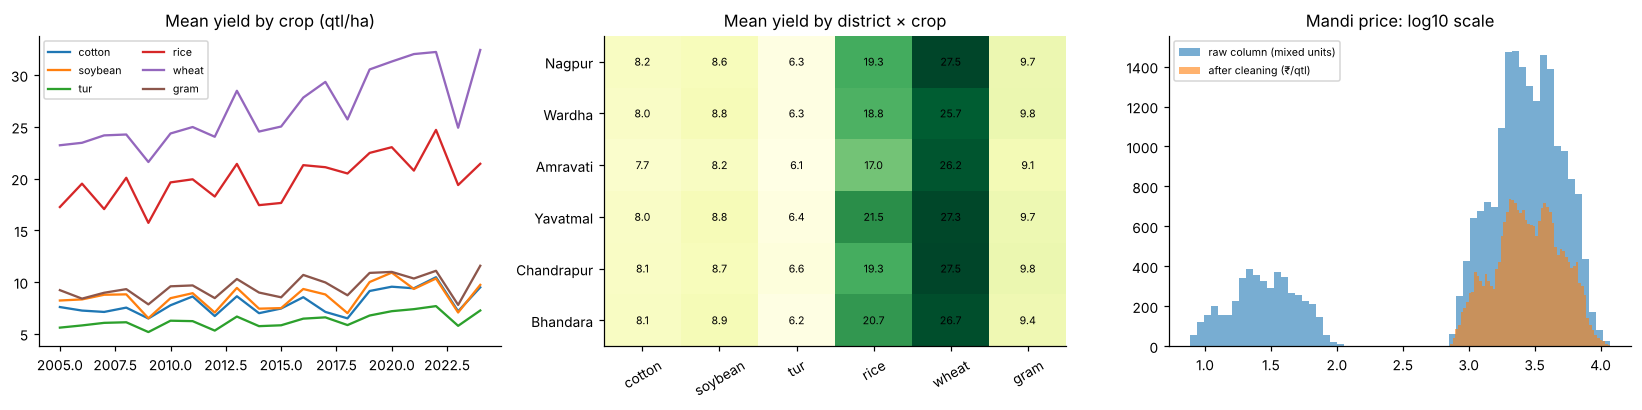

In [7]:
Y["season"] = Y.crop.map(SEASON)
print("Cleaned yield table:", Y.shape, "| years", Y.year.min(), "-", Y.year.max())
print(Y.groupby("crop").yield_qtl_ha.describe().round(2))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c in CROPS: ax[0].plot(Y[Y.crop == c].groupby("year").yield_qtl_ha.mean(), label=c)
ax[0].set_title("Mean yield by crop (qtl/ha)"); ax[0].legend(ncol=2, fontsize=7)
hm = Y.groupby(["district", "crop"]).yield_qtl_ha.mean().unstack()[CROPS].loc[DIST]
im = ax[1].imshow(hm.values, cmap="YlGn", aspect="auto"); ax[1].set_xticks(range(6)); ax[1].set_xticklabels(CROPS, rotation=30); ax[1].set_yticks(range(6)); ax[1].set_yticklabels(DIST)
for i in range(6):
    for j in range(6): ax[1].text(j, i, f"{hm.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax[1].set_title("Mean yield by district × crop")
ax[2].hist(np.log10(raw["mandi"].modal_price), bins=60, alpha=.6, label="raw column (mixed units)"); ax[2].hist(np.log10(M.price_qtl), bins=60, alpha=.6, label="after cleaning (₹/qtl)")
ax[2].set_title("Mandi price: log10 scale"); ax[2].legend(fontsize=7)
savefig("eda_1_yield_price"); plt.show()

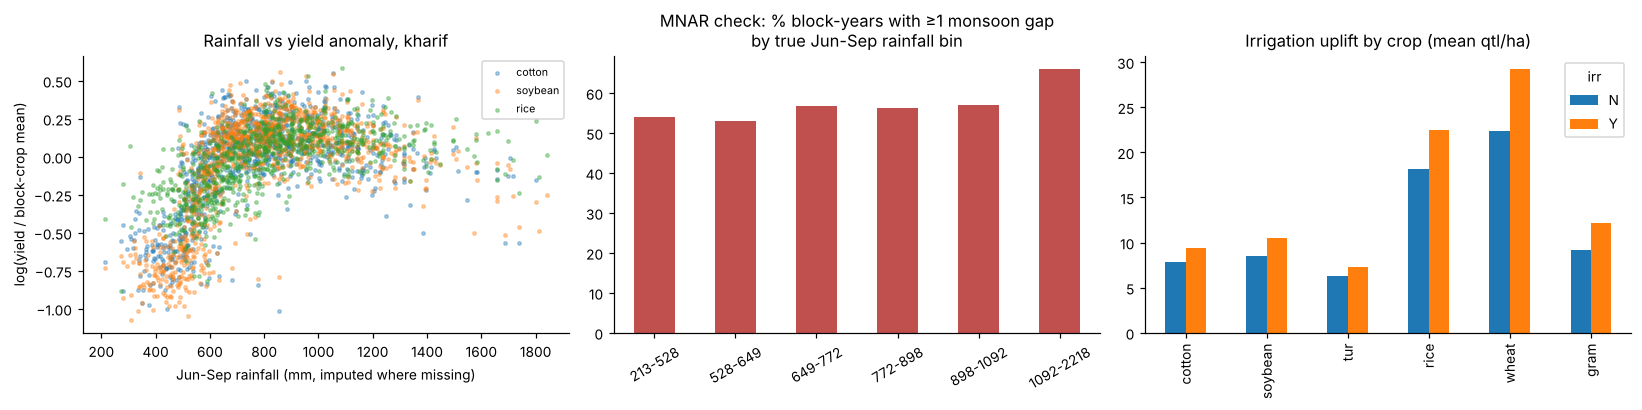

Corr(Jun-Sep rain, log yield anomaly) by crop: {'cotton': 0.48, 'gram': 0.53, 'rice': 0.55, 'soybean': 0.51, 'tur': 0.33, 'wheat': 0.43}

Yield CV (std/mean) by crop: {'cotton': 0.33, 'gram': 0.29, 'rice': 0.3, 'soybean': 0.35, 'tur': 0.29, 'wheat': 0.28}
Share rows with irrigated=NA: 3.0 % | fert_n missing: 23.1 % (small plots <1.5 ha: 30.0 % vs larger: 12.0 %)


In [8]:
# Rainfall vs yield anomaly (block-crop-year) for kharif crops, and missingness-vs-rain
Bn = Y.groupby(["block", "crop", "year"]).agg(y=("yield_qtl_ha", "mean"), district=("district", "first")).reset_index()
Bn["rel"] = Bn.y / Bn.groupby(["crop", "year"]).y.transform("mean") * 1.0
Bn["lyr"] = np.log(Bn.y / Bn.groupby(["block", "crop"]).y.transform("mean"))
Bn = Bn.merge(Wi[["block", "sy", "r_jun", "r_jul", "r_aug", "r_sep"]].assign(junsep=lambda d: d[["r_jun", "r_jul", "r_aug", "r_sep"]].sum(axis=1)), left_on=["block", "year"], right_on=["block", "sy"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c in ["cotton", "soybean", "rice"]:
    s = Bn[Bn.crop == c]; ax[0].scatter(s.junsep, s.lyr, s=5, alpha=.35, label=c)
ax[0].set_xlabel("Jun-Sep rainfall (mm, imputed where missing)"); ax[0].set_ylabel("log(yield / block-crop mean)"); ax[0].set_title("Rainfall vs yield anomaly, kharif"); ax[0].legend(fontsize=7)
true_js = RTW[["r_jun", "r_jul", "r_aug", "r_sep"]].sum(axis=1)
mm = Wraw[["block", "sy", "r_jun", "r_jul", "r_aug", "r_sep"]].merge(true_js.rename("true_js").reset_index(), on=["block", "sy"])
mm["any_missing"] = mm[["r_jun", "r_jul", "r_aug", "r_sep"]].isna().any(axis=1)
mm["bin"] = pd.qcut(mm.true_js, 6)
(mm.groupby("bin").any_missing.mean() * 100).plot.bar(ax=ax[1], color="#c0504d"); ax[1].set_title("MNAR check: % block-years with ≥1 monsoon gap\nby true Jun-Sep rainfall bin"); ax[1].set_xlabel("")
ax[1].set_xticklabels([f"{b.left:.0f}-{b.right:.0f}" for b in mm.groupby('bin').any_missing.mean().index], rotation=30)
s = Y.assign(irr=Y.irrigated.fillna("NA")); s["area_grp"] = pd.cut(s.plot_area_ha, [0, 1, 2, 100], labels=["<1 ha", "1-2 ha", ">2 ha"])
(s.groupby(["crop", "irr"]).yield_qtl_ha.mean().unstack()[["N", "Y"]].loc[CROPS]).plot.bar(ax=ax[2]); ax[2].set_title("Irrigation uplift by crop (mean qtl/ha)"); ax[2].set_xlabel("")
savefig("eda_2_rain_missing_irrigation"); plt.show()
cr = Bn.groupby("crop").apply(lambda d: d.junsep.corr(d.lyr)).round(2); print("Corr(Jun-Sep rain, log yield anomaly) by crop:", cr.to_dict())
METRICS["rain_yield_corr"] = {k: float(v) for k, v in cr.items()}
print("\nYield CV (std/mean) by crop:", (Y.groupby("crop").yield_qtl_ha.std() / Y.groupby("crop").yield_qtl_ha.mean()).round(2).to_dict())
print("Share rows with irrigated=NA:", round(100 * Y.irrigated.isna().mean(), 1), "% | fert_n missing:", round(100 * Y.fert_n_kgha.isna().mean(), 1), "% (small plots <1.5 ha:",
      round(100 * Y[Y.plot_area_ha < 1.5].fert_n_kgha.isna().mean(), 1), "% vs larger:", round(100 * Y[Y.plot_area_ha >= 1.5].fert_n_kgha.isna().mean(), 1), "%)")

**EDA take-aways.** (1) Yields trend upward ~1-1.4 %/yr and the district×crop map shows clear agronomic structure (Bhandara rice, Yavatmal cotton/tur). (2) Rainfall is strongly related to yield anomalies for rainfed kharif crops;
irrigation removes most of that sensitivity (wheat/rice uplift). (3) Rain-gauge gaps are *not* random: gaps cluster in the wettest bins (middle-right panel), so imputing the neighbour average
slightly under-states extreme rain; we keep a missing-count flag and report the imputation bias. (4) Small farms under-report fertiliser: missingness by farm size is itself a fairness-relevant fact.

## 4. Feature engineering
All features are **causal by construction**: yield lags use *previous* years; rolling stats are `shift(1)`-ed; climatologies and target encodings are *expanding past-only*; rainfall stops at the crop's forecast cutoff;
soil uses an as-of join to the latest test on/before the season. Features are grouped as **lag / rolling / ratio / encoded / raw**.

In [9]:
Y = Y.sort_values(["village_id", "crop", "year", "record_id"]).reset_index(drop=True)
Y["is_rabi"] = (Y.season == "rabi").astype(int)
# ---- yield aggregates and lags ------------------------------------------------------------
def lagroll(df, keys, val, pre):
    df = df.sort_values(keys + ["year"]).copy(); g = df.groupby(keys)[val]
    assert df.groupby(keys).year.diff().dropna().eq(1).all(), "gap in panel"
    df[f"{pre}_lag1"] = g.shift(1); df[f"{pre}_lag2"] = g.shift(2)
    df[f"{pre}_roll3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
    df[f"{pre}_roll3sd"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=2).std())
    df[f"{pre}_trail3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=3).mean())      # strict 3-yr baseline for shortfall flag
    return df
vcy = Y.groupby(["village_id", "crop", "year"]).agg(y_vc=("yield_qtl_ha", "mean"), n_vc=("yield_qtl_ha", "size"), block=("block", "first"), district=("district", "first")).reset_index()
bcy = Y.groupby(["block", "crop", "year"]).agg(y_bc=("yield_qtl_ha", "mean")).reset_index()
dcy = Y.groupby(["district", "crop", "year"]).agg(y_dc=("yield_qtl_ha", "mean")).reset_index()
vcy = lagroll(vcy, ["village_id", "crop"], "y_vc", "vc"); bcy = lagroll(bcy, ["block", "crop"], "y_bc", "bc"); dcy = lagroll(dcy, ["district", "crop"], "y_dc", "dc")
F = Y.merge(vcy[["village_id", "crop", "year", "y_vc", "vc_lag1", "vc_lag2", "vc_roll3", "vc_roll3sd"]], on=["village_id", "crop", "year"]) \
     .merge(bcy[["block", "crop", "year", "y_bc", "bc_lag1", "bc_roll3", "bc_trail3"]], on=["block", "crop", "year"]) \
     .merge(dcy[["district", "crop", "year", "y_dc", "dc_lag1", "dc_roll3"]], on=["district", "crop", "year"])
F["vc_yoy"] = F.vc_lag1 / F.vc_lag2 - 1                                  # ratio: last year's change
F["dc_lag1_rel"] = F.dc_lag1 / F.dc_roll3                                # ratio: how good/bad was last year district-wide
F["vc_lag1_vs_roll3"] = F.vc_lag1 / F.vc_roll3

# ---- rainfall (stops at the crop's cutoff) --------------------------------------------------
Wf = W.copy()
Wf["junsep"] = Wf[["r_jun", "r_jul", "r_aug", "r_sep"]].sum(axis=1)
Wf["octjan"] = Wf[["r_oct", "r_nov", "r_dec", "r_jan"]].sum(axis=1)
Wf["junsep_clim"] = Wf.groupby("block").junsep.transform(lambda s: s.shift(1).expanding(min_periods=2).mean())
Wf["rain_anom_pct"] = Wf.junsep / Wf.junsep_clim - 1                      # past-only climatology
Wf["junsep_lag1"] = Wf.groupby("block").junsep.shift(1)                   # last year's monsoon (groundwater carry-over)
Wf["rain_ja"] = Wf.r_jul + Wf.r_aug
Wf["rd_ja"] = Wf.rd_jul + Wf.rd_aug
Wf["rain_intensity"] = Wf.rain_ja / Wf.rd_ja.clip(lower=1)                # mm per rainy day, Jul-Aug
Wf["ja_share"] = Wf.rain_ja / Wf.junsep
Wf["post_cutoff_rain_kharif"] = Wf.r_oct + Wf.r_nov                       # LEAK candidates (after cutoff)
Wf["post_cutoff_rain_rabi"] = Wf.r_feb
keepW = ["block", "sy", "junsep", "octjan", "rain_anom_pct", "junsep_lag1", "rain_ja", "rd_ja", "rain_intensity", "ja_share", "r_jun", "r_sep", "rain_missing_monsoon", "post_cutoff_rain_kharif", "post_cutoff_rain_rabi"]
F = F.merge(Wf[keepW], left_on=["block", "year"], right_on=["block", "sy"], how="left").drop(columns="sy")
F["rain_cum"] = np.where(F.is_rabi == 1, F.junsep + F.octjan, F.junsep)             # to the forecast cutoff
F["rain_octjan"] = np.where(F.is_rabi == 1, F.octjan, np.nan)
F["rain_ratio_req"] = F.rain_cum / F.crop.map(WATER_REQ)                           # ratio: supply / agronomic requirement
F["post_cutoff_rain"] = np.where(F.is_rabi == 1, F.post_cutoff_rain_rabi, F.post_cutoff_rain_kharif)
F = F.drop(columns=["octjan", "post_cutoff_rain_kharif", "post_cutoff_rain_rabi"])

# ---- soil: as-of join to the latest test on/before the season ------------------------------------
S = raw["soil"].sort_values(["village_id", "test_year"]).copy()
S[["ph", "oc_pct", "n_kgha", "p_kgha", "k_kgha", "ec"]] = S.groupby("village_id")[["ph", "oc_pct", "n_kgha", "p_kgha", "k_kgha", "ec"]].ffill()
F = F.sort_values("year").reset_index(drop=True)
F = pd.merge_asof(F, S.sort_values("test_year"), left_on="year", right_on="test_year", by="village_id", direction="backward")
F["soil_age"] = F.year - F.test_year
F["soil_missing"] = F.ph.isna().astype(int)
F["n_p_ratio"] = F.n_kgha / F.p_kgha; F["n_k_ratio"] = F.n_kgha / F.k_kgha
F["ph_dev"] = (F.ph - F.crop.map(PH_OPT)).abs()

# ---- prices, cost ------------------------------------------------------------------------------
M["t"] = (M.year - 2005) * 12 + M.month - 1
P = M.groupby(["district", "crop", "t"]).price_qtl.mean().unstack("t")
P = P.reindex(columns=range(240)).ffill(axis=1).bfill(axis=1)             # district-crop monthly series (a few gaps filled from the past)
pl = P.stack().rename("price").reset_index()
def price_at(df, month_kh, month_rb, year_shift_kh=0, year_shift_rb=0):
    mo = np.where(df.is_rabi == 1, month_rb, month_kh); yr = df.year + np.where(df.is_rabi == 1, year_shift_rb, year_shift_kh)
    t = ((yr - 2005) * 12 + mo - 1).astype(int).clip(0, 239)
    return P.stack().reindex(pd.MultiIndex.from_arrays([df.district, df.crop, t])).values
F["price_pre_sow"] = price_at(F, 5, 10)                                   # May (kharif) / Oct (rabi)
t_pre = ((F.year - 2005) * 12 + np.where(F.is_rabi == 1, 10, 5) - 1).astype(int)
pm = P.T.rolling(36, min_periods=12).mean().shift(1).T                    # mean of previous 36 months
F["price_pre_mom"] = F.price_pre_sow / pm.stack().reindex(pd.MultiIndex.from_arrays([F.district, F.crop, t_pre])).values
F["price_prev_harvest"] = price_at(F, 11, 3, -1, 0)                       # last season's harvest-month price (known)
F["price_hv_prev_ratio"] = F.price_prev_harvest / F.price_pre_sow
F["price_harvest_cur"] = price_at(F, 11, 3, 0, 1)                         # LEAK candidate: this season's harvest-month price
C = raw["cost_index"].copy(); C["fert_idx_rel"] = C.fert_price_index / C.groupby("crop").fert_price_index.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
F = F.merge(C[["crop", "year", "cost_rs_per_ha", "fert_idx_rel"]], on=["crop", "year"], how="left")
F["price_to_cost"] = F.price_pre_sow * F.vc_roll3 / F.cost_rs_per_ha        # ratio: expected revenue/ha ÷ cost/ha
AS = raw["area_stats"][["district", "crop", "year", "sown_area_ha"]]; F = F.merge(AS, on=["district", "crop", "year"], how="left")

# ---- plot attributes -------------------------------------------------------------------------------
F["irrigated_flag"] = F.irrigated.map({"Y": 1, "N": 0})
F["area_log"] = np.log(F.plot_area_ha)
F["sow_delay"] = F.sowing_week - F.crop.map(SOW_OPT)
F["fert_n_rel"] = F.fert_n_kgha / F.crop.map(BASE_N)
F["fert_missing"] = F.fert_n_kgha.isna().astype(int)
F["crop_id"] = F.crop.map({c: i for i, c in enumerate(CROPS)}); F["district_id"] = F.district.map({d: i for i, d in enumerate(DIST)})

# ---- high-cardinality categoricals: past-only, smoothed target encoding ------------------------------
def past_smoothed(df, keys, val, w, m):
    """Expanding, strictly-past, shrunk mean of `val` by `keys` (weights w, pseudo-count m, prior 0)."""
    t = df.assign(_s=df[val] * df[w], _c=df[w]).groupby(keys + ["year"])[["_s", "_c"]].sum().reset_index().sort_values(keys + ["year"])
    cs = t.groupby(keys)[["_s", "_c"]].cumsum() - t[["_s", "_c"]]          # exclusive cumsum = years < current
    t["enc"] = cs["_s"] / (cs["_c"] + m); t["hist_n"] = cs["_c"]
    return df.merge(t[keys + ["year", "enc", "hist_n"]], on=keys + ["year"], how="left")
# village (720) x crop: relative productivity vs the district-crop-year mean
vrel = vcy.merge(dcy[["district", "crop", "year", "y_dc"]], on=["district", "crop", "year"]); vrel["lrel"] = np.log(vrel.y_vc / vrel.y_dc); vrel["w"] = 1.0
vrel = past_smoothed(vrel, ["village_id", "crop"], "lrel", "w", m=3).rename(columns={"enc": "village_te", "hist_n": "village_hist"})
F = F.merge(vrel[["village_id", "crop", "year", "village_te", "village_hist"]], on=["village_id", "crop", "year"], how="left")
# variety (72): within village-crop-year deviation, only from VCYs that grew >=2 varieties
F["ly"] = np.log(F.yield_qtl_ha); F["dev"] = F.ly - F.groupby(["village_id", "crop", "year"]).ly.transform("mean")
F["w_var"] = (F.groupby(["village_id", "crop", "year"]).variety.transform("nunique") > 1).astype(float)
ve = past_smoothed(F[["crop", "variety", "year", "dev", "w_var"]].copy(), ["crop", "variety"], "dev", "w_var", m=300)
ve = ve.drop_duplicates(["crop", "variety", "year"]).rename(columns={"enc": "variety_te", "hist_n": "variety_hist"})
F = F.merge(ve[["crop", "variety", "year", "variety_te", "variety_hist"]], on=["crop", "variety", "year"], how="left")
F["variety_age"] = F.year - F.groupby("variety").year.transform("min")     # years since the variety first appeared in the data
print("High-cardinality levels: village_id =", F.village_id.nunique(), "| variety =", F.variety.nunique(), "| block =", F.block.nunique())

High-cardinality levels: village_id = 720 | variety = 72 | block = 60


**A feature removed after review.** `fert_idx_rel` (fertiliser-price index relative to its 3-yr mean) takes one value per crop-year. A tree can use it as a *year ID* and memorise that year's weather shock, which would
look good in training and fail on new years, so it is excluded from the model (it still feeds the ratio `price_to_cost`).

In [10]:
FEATS = {
 "lag":      ["vc_lag1", "vc_lag2", "bc_lag1", "dc_lag1", "junsep_lag1", "price_prev_harvest"],
 "rolling":  ["vc_roll3", "vc_roll3sd", "bc_roll3", "dc_roll3"],
 "ratio":    ["vc_yoy", "dc_lag1_rel", "vc_lag1_vs_roll3", "rain_ratio_req", "rain_anom_pct", "ja_share", "rain_intensity", "n_p_ratio", "n_k_ratio",
              "ph_dev", "price_pre_mom", "price_hv_prev_ratio", "price_to_cost", "fert_n_rel", "sow_delay"],
 "weather":  ["rain_cum", "junsep", "rain_ja", "r_jun", "r_sep", "rain_octjan", "rd_ja", "rain_missing_monsoon"],
 "soil":     ["ph", "oc_pct", "n_kgha", "p_kgha", "k_kgha", "ec", "soil_age", "soil_missing"],
 "encoded":  ["village_te", "village_hist", "variety_te", "variety_age"],
 "plot":     ["area_log", "irrigated_flag", "fert_n_kgha", "fert_missing", "sowing_week"],
 "category": ["crop_id", "district_id", "is_rabi"],
}
FEAT = [f for g in FEATS.values() for f in g]
print(len(FEAT), "model features |", {k: len(v) for k, v in FEATS.items()})
ENG_RATIO_LAG_ROLL = sum(len(FEATS[k]) for k in ("lag", "rolling", "ratio"))
METRICS["n_features"] = len(FEAT); METRICS["n_lag_roll_ratio"] = ENG_RATIO_LAG_ROLL
F = F[F.year >= 2007].reset_index(drop=True)                               # first two years are burn-in for lags
F["y"] = F.yield_qtl_ha
print("Modelling rows:", len(F), "| NaN share by feature (top):"); print((100 * F[FEAT].isna().mean()).round(1).sort_values(ascending=False).head(10).to_dict())

53 model features | {'lag': 6, 'rolling': 4, 'ratio': 15, 'weather': 8, 'soil': 8, 'encoded': 4, 'plot': 5, 'category': 3}
Modelling rows: 263386 | NaN share by feature (top):
{'rain_octjan': 72.2, 'fert_n_rel': 23.2, 'fert_n_kgha': 23.2, 'n_k_ratio': 11.6, 'n_p_ratio': 11.4, 'ec': 11.0, 'oc_pct': 10.9, 'k_kgha': 10.9, 'ph': 10.9, 'ph_dev': 10.9}


**Missing-value policy.** Tree models (LightGBM, random forest in scikit-learn ≥1.4) use native NaN routing; the linear model uses median imputation fitted *on the training window only*, plus the explicit
missing-flags (`soil_missing`, `fert_missing`, `rain_missing_monsoon`). **High-cardinality policy.** `village_id` (720) and `variety` (72) are never one-hot encoded: they enter as *past-only shrunk target encodings*
(`village_te`, `variety_te`) plus counts, so an unseen village or a brand-new variety falls back to the prior (0) instead of an arbitrary code.

## 5. Leakage audit
Three checks: (a) **timing audit**: for each candidate column, is it known at the forecast cutoff? (b) **empirical audit**: does it track the target suspiciously well? (c) **experiment**: how much does the model "improve" if the leaky columns are admitted?

In [11]:
from scipy.stats import spearmanr
F["claim"] = (F.insurance_claim_paid == "Y").astype(int)
cand = {"production_qtl": "No: post-harvest (= yield × area)", "insurance_claim_paid": "No: paid after harvest loss assessment", "price_harvest_cur": "No: harvest-month price, set by this season's supply",
        "post_cutoff_rain": "No: rain after the forecast cutoff", "vc_lag1": "Yes: last season", "rain_cum": "Yes: to cutoff", "price_pre_sow": "Yes: pre-sowing", "oc_pct": "Yes: soil test"}
rows = []
for c, why in cand.items():
    x = F[c].astype(float) if c != "insurance_claim_paid" else F.claim.astype(float)
    r = F.assign(x=x).dropna(subset=["x"]).groupby("crop").apply(lambda d: spearmanr(d.x, d.y)[0]).abs().mean()
    rows.append(dict(column=c, mean_abs_spearman_within_crop=round(r, 3), known_at_cutoff=why))
leak_tbl = pd.DataFrame(rows); print(leak_tbl.to_string(index=False)); METRICS["leak_table"] = leak_tbl.to_dict("records")

              column  mean_abs_spearman_within_crop                                      known_at_cutoff
      production_qtl                          0.409                    No: post-harvest (= yield × area)
insurance_claim_paid                          0.592               No: paid after harvest loss assessment
   price_harvest_cur                          0.134 No: harvest-month price, set by this season's supply
    post_cutoff_rain                          0.151                   No: rain after the forecast cutoff
             vc_lag1                          0.213                                     Yes: last season
            rain_cum                          0.419                                       Yes: to cutoff
       price_pre_sow                          0.248                                      Yes: pre-sowing
              oc_pct                          0.213                                       Yes: soil test


In [12]:
import lightgbm as lgb
tr_ = F[F.year <= 2019].sample(60000, random_state=RNG); va_ = F[F.year.between(2020, 2021)]
def quick_mae(cols):
    m = lgb.LGBMRegressor(n_estimators=150, learning_rate=.1, num_leaves=31, verbose=-1, random_state=RNG, n_jobs=1).fit(tr_[cols], tr_.y)
    return np.abs(m.predict(va_[cols]) - va_.y).mean()
leaky = ["production_qtl", "claim", "price_harvest_cur", "post_cutoff_rain"]
Fl = F.copy(); Fl["prod_per_ha_proxy"] = Fl.production_qtl / Fl.plot_area_ha
mae_clean = quick_mae(FEAT); mae_leak = quick_mae(FEAT + leaky)
tr_ = F[F.year <= 2019].sample(60000, random_state=RNG)
print(f"Validation MAE with clean features   : {mae_clean:.3f} qtl/ha\nValidation MAE with leaky columns    : {mae_leak:.3f} qtl/ha  (a 'too good to be true' drop)")
mae_leak_no_prod = quick_mae(FEAT + ["claim", "price_harvest_cur", "post_cutoff_rain"])
print(f"...even without production_qtl      : {mae_leak_no_prod:.3f} qtl/ha")
METRICS["leak_mae_clean"] = float(mae_clean); METRICS["leak_mae_leaky"] = float(mae_leak); METRICS["leak_mae_leaky_no_prod"] = float(mae_leak_no_prod)
# causality unit test: brute-force recompute lag/rolling features for random rows
rs = F.sample(300, random_state=1); ok = 0
for _, r in rs.iterrows():
    h = vcy[(vcy.village_id == r.village_id) & (vcy.crop == r.crop)].set_index("year").y_vc
    ok += int(np.isclose(h.get(r.year - 1), r.vc_lag1) and np.isclose(h.loc[r.year - 3:r.year - 1].mean() if r.year >= 2008 else h.loc[r.year - 2:r.year - 1].mean(), r.vc_roll3))
print(f"Causality unit test: {ok}/300 sampled rows reproduce lag1 and roll3 from strictly earlier years")
assert ok == 300
METRICS["causality_test"] = f"{ok}/300"
LEAK_COLS = leaky + ["insurance_claim_paid"]

Validation MAE with clean features   : 2.193 qtl/ha
Validation MAE with leaky columns    : 0.917 qtl/ha  (a 'too good to be true' drop)


...even without production_qtl      : 2.126 qtl/ha


Causality unit test: 300/300 sampled rows reproduce lag1 and roll3 from strictly earlier years


**Leakage verdict.** `production_qtl` (= yield × area), `insurance_claim_paid`, the harvest-month mandi price and post-cutoff rain are all rejected. The experiment shows why it matters: admitting them produces a large, fake improvement.
Mandi price deserves a note: it *is* useful **before** sowing (price signals, price-to-cost) but the *harvest-month* price already embeds this season's supply shock, so it is leakage for yield prediction.

## 6. Time-aware split
* **Train** 2007-2019 (13 seasons) · **Validation** 2020-2021 · **Test** 2022-2024 (touched once, at the end).
* No random shuffling: random splits would let the model see the same village in the same year, and neighbouring blocks under the same weather.
* Cross-validation inside train is **expanding-window**: fit ≤2013 → score 2014-15; fit ≤2015 → 2016-17; fit ≤2017 → 2018-19.
* Because all features are past-only, one feature matrix is valid for every split; the encodings never see a validation or test year.

In [13]:
TRAIN_Y, VAL_Y, TEST_Y = (2007, 2019), (2020, 2021), (2022, 2024)
tr = F[F.year.between(*TRAIN_Y)]; va = F[F.year.between(*VAL_Y)]; te = F[F.year.between(*TEST_Y)]
FOLDS = [((2007, 2013), (2014, 2015)), ((2007, 2015), (2016, 2017)), ((2007, 2017), (2018, 2019))]
split_tbl = pd.DataFrame({"split": ["train", "validation", "test"], "years": ["2007-2019", "2020-2021", "2022-2024"], "rows": [len(tr), len(va), len(te)], "mean_yield_qtl_ha": [tr.y.mean(), va.y.mean(), te.y.mean()]}).round(2)
print(split_tbl.to_string(index=False)); assert tr.year.max() < va.year.min() <= va.year.max() < te.year.min()
METRICS["split_rows"] = {"train": len(tr), "val": len(va), "test": len(te)}; METRICS["rows_modelling"] = len(F)
# adversarial validation: can a classifier tell train rows from test rows?
from sklearn.metrics import roc_auc_score
adv = pd.concat([tr.sample(40000, random_state=1).assign(a=0), te.sample(40000, random_state=1).assign(a=1)])
idx = np.random.RandomState(0).rand(len(adv)) < .7
LEVEL = ["vc_lag1", "vc_lag2", "bc_lag1", "dc_lag1", "vc_roll3", "vc_roll3sd", "bc_roll3", "dc_roll3", "price_prev_harvest", "fert_n_kgha", "n_kgha", "p_kgha", "k_kgha", "oc_pct", "village_hist", "variety_hist", "variety_age", "soil_age", "sowing_week"]
def adv_auc(cols):
    ma = lgb.LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=.1, verbose=-1, n_jobs=1).fit(adv[cols][idx], adv.a[idx])
    return roc_auc_score(adv.a[~idx], ma.predict_proba(adv[cols][~idx])[:, 1]), pd.Series(ma.feature_importances_, cols).sort_values(ascending=False).head(4).index.tolist()
auc_all, top_all = adv_auc(FEAT); auc_st, top_st = adv_auc([c for c in FEAT if c not in LEVEL])
print(f"Adversarial validation AUC (train vs test): all features = {auc_all:.3f} (top: {top_all}); without level/trend features = {auc_st:.3f} (top: {top_st})")
METRICS["adv_auc"] = float(auc_all); METRICS["adv_auc_stationary"] = float(auc_st); METRICS["adv_top"] = top_all

     split     years   rows  mean_yield_qtl_ha
     train 2007-2019 190201              11.75
validation 2020-2021  29291              13.99
      test 2022-2024  43894              13.36


Adversarial validation AUC (train vs test): all features = 1.000 (top: ['vc_lag1', 'vc_lag2', 'village_hist', 'junsep_lag1']); without level/trend features = 1.000 (top: ['dc_lag1_rel', 'price_pre_mom', 'price_hv_prev_ratio', 'district_id'])


## 7. Metrics that match the business cost of errors
Procurement is planned per **block-crop** and rolled up to district, so errors that matter are errors in the *average* yield of a block-crop-season, not plot-to-plot noise.
**Agreed before modelling:**
* **Primary metric: MAE in quintal/ha at block-crop-year level** (`MAE_bcy`), compared with the naive persistence baseline (last year's yield for the same village-crop). Success = **≥15 % lower**.
* **Business metric 2: recall at ≥70 % precision** for flagging a *shortfall* block-crop-year (actual yield < 85 % of its trailing 3-year mean). A missed shortfall (false negative) leaves a procurement
  commitment unfilled; a false alarm only wastes some safety stock, so we fix precision at 70 % and maximise recall. The score threshold is chosen on **validation** and applied unchanged to test.
* Secondary: plot-level MAE/RMSE, tonnage error at district-crop level.
* **Target.** Yields trend upward and trees cannot extrapolate, so every ML model predicts `log(yield / 3-year village-crop mean)` (stationary) and the forecast is `mean3 × exp(prediction)`. Metrics are always on the original qtl/ha scale.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_recall_curve, average_precision_score
import lightgbm as lgb, joblib

F["ref"] = F.vc_roll3; F["tgt"] = np.log(F.y / F.ref)
assert F.ref.notna().all() and np.isfinite(F.tgt).all()
tr = F[F.year.between(*TRAIN_Y)]; va = F[F.year.between(*VAL_Y)]; te = F[F.year.between(*TEST_Y)]
SHORT = 0.85                                    # shortfall = actual < 85% of trailing 3-yr block-crop mean
PREC = 0.70

def bcy_table(df, p):
    return (df.assign(p=p).groupby(["district", "block", "crop", "year"]).agg(y=("y", "mean"), p=("p", "mean"), trail3=("bc_trail3", "first"), n=("y", "size")).reset_index())
def basic(df, p):
    b = bcy_table(df, p)
    return dict(MAE_bcy=float((b.y - b.p).abs().mean()), MAE_row=float((df.y - p).abs().mean()), RMSE_row=float(np.sqrt(((df.y - p) ** 2).mean())))
def shortfall_frame(df, p):
    b = bcy_table(df, p).dropna(subset=["trail3"]); b["actual"] = (b.y < SHORT * b.trail3).astype(int); b["score"] = 1 - b.p / b.trail3
    return b
def pick_threshold(b, min_prec=PREC):
    pr, rc, th = precision_recall_curve(b.actual, b.score)
    ok = np.where(pr[:-1] >= min_prec)[0]
    if len(ok) == 0: return None
    i = ok[np.argmax(rc[ok])]; return float(th[i])
def recall_at(b, thr):
    if thr is None: return dict(precision=np.nan, recall=0.0, flagged=0)
    f = b.score >= thr; tp = int((f & (b.actual == 1)).sum())
    return dict(precision=tp / max(1, int(f.sum())) if f.sum() else np.nan, recall=tp / max(1, int(b.actual.sum())), flagged=int(f.sum()))
def full_eval(df, p, thr=None):
    out = basic(df, p); b = shortfall_frame(df, p)
    out["AP"] = float(average_precision_score(b.actual, b.score)) if b.actual.sum() else np.nan
    out["base_rate"] = float(b.actual.mean()); out["n_bcy"] = len(b)
    return out, b

## 8. Models and expanding-window cross-validation
Baselines and models, all scored on the same three folds: **(0)** persistence: last year's village-crop yield (the agreed baseline) and a stronger 3-year mean; **(1)** per-crop **Ridge** regression (linear, median-imputed,
winsorised, standardised, district dummies); **(2)** **Random forest**; **(3)** **LightGBM** (gradient boosting, default settings).

In [15]:
LIN = [f for f in FEAT if f not in ("crop_id", "is_rabi", "district_id")]
def lin_X(df, bounds=None):
    X = df[LIN].astype(float).copy()
    if bounds is None: bounds = (X.quantile(.01), X.quantile(.99))
    X = X.clip(bounds[0], bounds[1], axis=1)
    for i in range(6): X[f"d{i}"] = (df.district_id.values == i).astype(float)
    return X, bounds
def fit_ridge(trn, alpha=30.):
    ms = {}
    for c, d in trn.groupby("crop_id"):
        X, bnd = lin_X(d); pipe = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), Ridge(alpha=alpha)).fit(X, d.tgt)
        ms[c] = (pipe, bnd)
    return ms
def pred_ridge(ms, df):
    out = np.zeros(len(df)); 
    for c, (pipe, bnd) in ms.items():
        m = (df.crop_id.values == c)
        if m.any(): out[m] = pipe.predict(lin_X(df[m], bnd)[0])
    return out
NT_RF = 12 if QUICK else 60
def fit_rf(trn):
    return RandomForestRegressor(n_estimators=NT_RF, min_samples_leaf=30, max_features=.4, max_samples=.25, n_jobs=1, random_state=RNG).fit(trn[FEAT], trn.tgt)
LGB_DEFAULT = dict(n_estimators=60 if QUICK else 400, learning_rate=.05, num_leaves=31, min_child_samples=50, subsample=.8, subsample_freq=1, colsample_bytree=.8, objective="regression")
def fit_lgb(trn, **kw):
    p = {**LGB_DEFAULT, **kw}
    return lgb.LGBMRegressor(**p, verbose=-1, random_state=RNG, n_jobs=1).fit(trn[FEAT], trn.tgt, categorical_feature=["crop_id", "district_id"])
rel_pred = lambda df, t: df.ref.values * np.exp(t)
MODELS = {
    "Persistence (last yr)":  lambda trn, tst: None,
    "3-yr mean":              lambda trn, tst: None,
    "Ridge (per crop)":       lambda trn, tst: rel_pred(tst, pred_ridge(fit_ridge(trn), tst)),
    "Random forest":          lambda trn, tst: rel_pred(tst, fit_rf(trn).predict(tst[FEAT])),
    "LightGBM (default)":     lambda trn, tst: rel_pred(tst, fit_lgb(trn).predict(tst[FEAT])),
}
def model_pred(name, trn, tst):
    if name.startswith("Persistence"): return tst.vc_lag1.values
    if name.startswith("3-yr"): return tst.vc_roll3.values
    return MODELS[name](trn, tst)
t0 = time.time(); cv_rows = []
for (a, b), (c, d) in FOLDS:
    trn = F[F.year.between(a, b)]; tst = F[F.year.between(c, d)]
    if QUICK: trn = trn.sample(frac=.2, random_state=1)
    for name in MODELS:
        cv_rows.append(dict(model=name, fold=f"{c}-{d}", **basic(tst, model_pred(name, trn, tst))))
    print("fold", c, d, "done", round(time.time() - t0), "s")
cv = pd.DataFrame(cv_rows)
cv_sum = cv.groupby("model", sort=False).agg(MAE_bcy_mean=("MAE_bcy", "mean"), MAE_bcy_sd=("MAE_bcy", "std"), MAE_row_mean=("MAE_row", "mean")).round(3)
base_cv = cv_sum.loc["Persistence (last yr)", "MAE_bcy_mean"]; cv_sum["vs_persistence_%"] = (100 * (1 - cv_sum.MAE_bcy_mean / base_cv)).round(1)
print(cv_sum); print(cv.pivot(index="model", columns="fold", values="MAE_bcy").round(3).loc[list(MODELS)])
METRICS["cv"] = cv_sum.reset_index().to_dict("records")
ml = cv_sum.drop(index=["Persistence (last yr)", "3-yr mean"]); BEST = ml.MAE_bcy_mean.idxmin(); print("Best by CV (primary metric):", BEST)

fold 2014 2015 done 21 s


fold 2016 2017 done 48 s


fold 2018 2019 done 83 s
                       MAE_bcy_mean  MAE_bcy_sd  MAE_row_mean  vs_persistence_%
model                                                                          
Persistence (last yr)         2.986       0.375         3.528               0.0
3-yr mean                     2.449       0.097         3.025              18.0
Ridge (per crop)              1.807       0.069         2.364              39.5
Random forest                 1.507       0.158         2.035              49.5
LightGBM (default)            1.433       0.049         1.946              52.0
fold                   2014-2015  2016-2017  2018-2019
model                                                 
Persistence (last yr)      2.877      2.678      3.403
3-yr mean                  2.404      2.383      2.561
Ridge (per crop)           1.796      1.881      1.744
Random forest              1.368      1.679      1.473
LightGBM (default)         1.398      1.489      1.414
Best by CV (primary metric): L

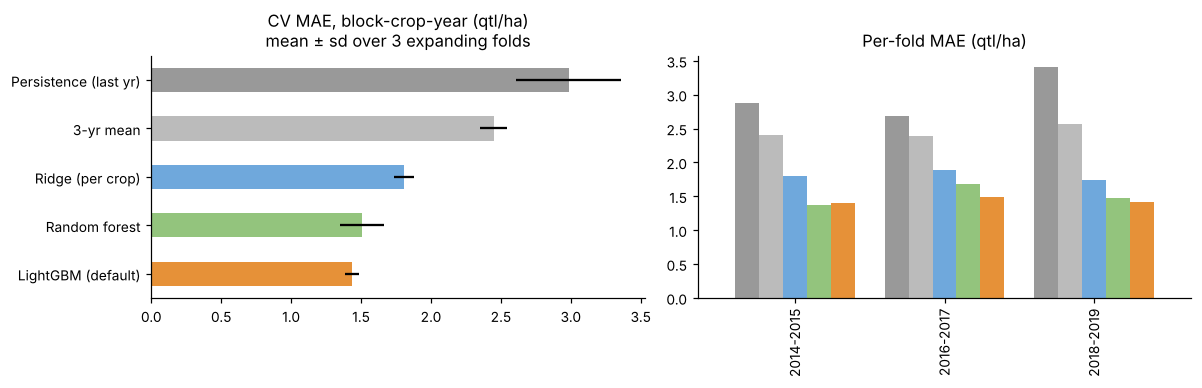

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cv_sum.MAE_bcy_mean.plot.barh(ax=ax[0], xerr=cv_sum.MAE_bcy_sd, color=["#999", "#bbb", "#6fa8dc", "#93c47d", "#e69138"]); ax[0].invert_yaxis(); ax[0].set_title("CV MAE, block-crop-year (qtl/ha)\nmean ± sd over 3 expanding folds"); ax[0].set_ylabel("")
cv.pivot(index="fold", columns="model", values="MAE_bcy")[list(MODELS)].plot.bar(ax=ax[1], width=.8, color=["#999", "#bbb", "#6fa8dc", "#93c47d", "#e69138"], legend=False); ax[1].set_title("Per-fold MAE (qtl/ha)"); ax[1].set_xlabel("")
savefig("cv_comparison"); plt.show()

## 8b. Tuning the best model
Random search (10 configurations, objective ∈ {L2, L1, Huber}) scored by the same expanding-window CV on the primary metric. Validation and test years are not used for tuning.

In [17]:
assert BEST.startswith("LightGBM"), f"best model is {BEST}; tuning code below is for LightGBM"
space = dict(num_leaves=[15, 31, 63, 127], learning_rate=[.03, .05, .08], n_estimators=[300, 500, 700], min_child_samples=[20, 50, 100, 200],
             subsample=[.6, .7, .8, .9], colsample_bytree=[.5, .6, .8, .9], reg_lambda=[0, 1, 5, 20], objective=["regression", "regression_l1", "huber"])
rs = np.random.RandomState(7); NCFG = 2 if QUICK else 10
cfgs = [{k: v[rs.randint(len(v))] for k, v in space.items()} for _ in range(NCFG)]
if QUICK: [c.update(n_estimators=40) for c in cfgs]
res = []; t0 = time.time()
for i, cfg in enumerate(cfgs):
    ms = []
    for (a, b), (c, d) in FOLDS:
        trn = F[F.year.between(a, b)]; tst = F[F.year.between(c, d)]
        if QUICK: trn = trn.sample(frac=.2, random_state=1)
        ms.append(basic(tst, rel_pred(tst, fit_lgb(trn, **cfg).predict(tst[FEAT])))["MAE_bcy"])
    res.append({**cfg, "cv_MAE_bcy": np.mean(ms), "cv_sd": np.std(ms)}); print(i, round(time.time() - t0), "s", round(np.mean(ms), 4), cfg)
tune = pd.DataFrame(res).sort_values("cv_MAE_bcy").reset_index(drop=True); print(tune.round(4).head(5).to_string())
BEST_CFG = {k: (tune.loc[0, k].item() if hasattr(tune.loc[0, k], "item") else tune.loc[0, k]) for k in space}
dflt = float(cv_sum.loc["LightGBM (default)", "MAE_bcy_mean"]); tuned = float(tune.loc[0, "cv_MAE_bcy"])
print(f"\nDefault LightGBM CV MAE_bcy {dflt:.4f} → tuned {tuned:.4f} ({100 * (1 - tuned / dflt):.1f}% better)  | chosen: {BEST_CFG}")
METRICS["tuning"] = dict(default_cv=dflt, tuned_cv=tuned, config={k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v)) for k, v in BEST_CFG.items()}, n_configs=NCFG)
USE_TUNED = tuned < dflt
FINAL_CFG = BEST_CFG if USE_TUNED else {}
print("Final model:", "tuned LightGBM" if USE_TUNED else "default LightGBM")

0 59 s 1.4349 {'num_leaves': 127, 'learning_rate': 0.03, 'n_estimators': 500, 'min_child_samples': 100, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 20, 'objective': 'regression'}


1 77 s 1.4338 {'num_leaves': 31, 'learning_rate': 0.08, 'n_estimators': 300, 'min_child_samples': 50, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5, 'objective': 'regression'}


2 107 s 1.4429 {'num_leaves': 127, 'learning_rate': 0.08, 'n_estimators': 300, 'min_child_samples': 20, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 0, 'objective': 'regression'}


3 176 s 1.4515 {'num_leaves': 127, 'learning_rate': 0.08, 'n_estimators': 700, 'min_child_samples': 200, 'subsample': 0.6, 'colsample_bytree': 0.5, 'reg_lambda': 20, 'objective': 'regression_l1'}


4 201 s 1.4651 {'num_leaves': 15, 'learning_rate': 0.03, 'n_estimators': 500, 'min_child_samples': 20, 'subsample': 0.9, 'colsample_bytree': 0.6, 'reg_lambda': 0, 'objective': 'huber'}


5 230 s 1.4705 {'num_leaves': 15, 'learning_rate': 0.05, 'n_estimators': 700, 'min_child_samples': 100, 'subsample': 0.6, 'colsample_bytree': 0.8, 'reg_lambda': 1, 'objective': 'regression'}


6 289 s 1.4377 {'num_leaves': 127, 'learning_rate': 0.03, 'n_estimators': 500, 'min_child_samples': 20, 'subsample': 0.6, 'colsample_bytree': 0.8, 'reg_lambda': 20, 'objective': 'regression_l1'}


7 306 s 1.4752 {'num_leaves': 15, 'learning_rate': 0.03, 'n_estimators': 300, 'min_child_samples': 200, 'subsample': 0.9, 'colsample_bytree': 0.8, 'reg_lambda': 1, 'objective': 'regression'}


8 326 s 1.4582 {'num_leaves': 31, 'learning_rate': 0.03, 'n_estimators': 300, 'min_child_samples': 50, 'subsample': 0.6, 'colsample_bytree': 0.9, 'reg_lambda': 1, 'objective': 'regression_l1'}


9 378 s 1.431 {'num_leaves': 127, 'learning_rate': 0.03, 'n_estimators': 500, 'min_child_samples': 200, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 1, 'objective': 'regression_l1'}
   num_leaves  learning_rate  n_estimators  min_child_samples  subsample  colsample_bytree  reg_lambda      objective  cv_MAE_bcy   cv_sd
0         127           0.03           500                200        0.8               0.6           1  regression_l1      1.4310  0.0676
1          31           0.08           300                 50        0.8               0.8           5     regression      1.4338  0.0516
2         127           0.03           500                100        0.9               0.9          20     regression      1.4349  0.0613
3         127           0.03           500                 20        0.6               0.8          20  regression_l1      1.4377  0.0735
4         127           0.08           300                 20        0.9               0.9           0     regressio

## 9. Evaluation: train → validation, then the test period (touched once)
All models are re-fitted on the full training window (2007-2019). The shortfall threshold (precision ≥ 70 %) is chosen on validation only.

In [18]:
t0 = time.time()
trn_full = tr.sample(frac=.2, random_state=1) if QUICK else tr
final_models = {"Ridge (per crop)": fit_ridge(trn_full), "Random forest": fit_rf(trn_full), "LightGBM (default)": fit_lgb(trn_full), "LightGBM (tuned)": fit_lgb(trn_full, **FINAL_CFG)}
print("fitted in", round(time.time() - t0), "s")
def predict_final(name, df):
    if name.startswith("Persistence"): return df.vc_lag1.values
    if name.startswith("3-yr"): return df.vc_roll3.values
    m = final_models[name]
    return rel_pred(df, pred_ridge(m, df) if name.startswith("Ridge") else m.predict(df[FEAT]))
ORDER = ["Persistence (last yr)", "3-yr mean", "Ridge (per crop)", "Random forest", "LightGBM (default)", "LightGBM (tuned)"]
val_res, thr = {}, {}
for n in ORDER:
    r, b = full_eval(va, predict_final(n, va)); thr[n] = pick_threshold(b) if n != "3-yr mean" else None
    r.update({f"val_{k}": v for k, v in recall_at(b, thr[n]).items()}); val_res[n] = r
vdf = pd.DataFrame(val_res).T; vdf["MAE_bcy_improv_%"] = 100 * (1 - vdf.MAE_bcy / vdf.loc["Persistence (last yr)", "MAE_bcy"])
print("VALIDATION (2020-2021)"); print(vdf[["MAE_bcy", "MAE_row", "RMSE_row", "MAE_bcy_improv_%", "AP", "val_precision", "val_recall", "val_flagged", "base_rate"]].astype(float).round(3))
METRICS["val"] = {n: {k: (float(v) if v is not None and v == v else None) for k, v in r.items()} for n, r in val_res.items()}; METRICS["val_n_bcy"] = int(val_res["LightGBM (tuned)"]["n_bcy"])

fitted in 61 s


VALIDATION (2020-2021)
                       MAE_bcy  MAE_row  RMSE_row  MAE_bcy_improv_%     AP  val_precision  val_recall  val_flagged  base_rate
Persistence (last yr)    2.108    2.826     4.093             0.000  0.139            NaN       0.000          0.0      0.109
3-yr mean                2.311    2.913     4.092            -9.630  0.116            NaN       0.000          0.0      0.109
Ridge (per crop)         1.994    2.503     3.493             5.417  0.575          0.706       0.333         34.0      0.109
Random forest            1.532    2.062     3.058            27.309  0.724          0.703       0.625         64.0      0.109
LightGBM (default)       1.538    2.004     2.998            27.011  0.745          0.708       0.639         65.0      0.109
LightGBM (tuned)         1.500    1.981     2.967            28.845  0.749          0.703       0.625         64.0      0.109


In [19]:
# ---------- TEST (2022-2024): one evaluation of every candidate, thresholds frozen from validation ----------
test_res, test_b = {}, {}
for n in ORDER:
    r, b = full_eval(te, predict_final(n, te)); r.update({f"test_{k}": v for k, v in recall_at(b, thr[n]).items()}); test_res[n] = r; test_b[n] = b
tdf = pd.DataFrame(test_res).T; tdf["MAE_bcy_improv_%"] = 100 * (1 - tdf.MAE_bcy / tdf.loc["Persistence (last yr)", "MAE_bcy"])
print("TEST (2022-2024)"); print(tdf[["MAE_bcy", "MAE_row", "RMSE_row", "MAE_bcy_improv_%", "AP", "test_precision", "test_recall", "test_flagged", "base_rate"]].astype(float).round(3))
METRICS["test"] = {n: {k: (float(v) if v is not None and v == v else None) for k, v in r.items()} for n, r in test_res.items()}; METRICS["test_n_bcy"] = int(test_res["LightGBM (tuned)"]["n_bcy"])
FIN = "LightGBM (tuned)"
v_m, t_m = val_res[FIN]["MAE_bcy"], test_res[FIN]["MAE_bcy"]
imp_val = 100 * (1 - v_m / val_res["Persistence (last yr)"]["MAE_bcy"]); imp_test = 100 * (1 - t_m / test_res["Persistence (last yr)"]["MAE_bcy"])
gap = 100 * (t_m / v_m - 1)
rec_b_t = test_res["Persistence (last yr)"]["test_recall"]; rec_m_t = test_res[FIN]["test_recall"]
print(f"\nSUCCESS CRITERIA\n 1. Beat baseline by ≥15% (MAE_bcy): validation {imp_val:.1f}% | test {imp_test:.1f}%  → {'PASS' if min(imp_val, imp_test) >= 15 else 'FAIL'}"
      f"\n 2. Test within 5% of validation: MAE_bcy val {v_m:.3f} vs test {t_m:.3f} → {gap:+.1f}%  → {'PASS' if abs(gap) <= 5 else 'FAIL'}"
      f"\n    (plot-level MAE: val {val_res[FIN]['MAE_row']:.3f} vs test {test_res[FIN]['MAE_row']:.3f} → {100 * (test_res[FIN]['MAE_row'] / val_res[FIN]['MAE_row'] - 1):+.1f}%)"
      f"\n 3. Recall @ precision≥70%: baseline test recall {rec_b_t:.2f} vs model {rec_m_t:.2f}")
METRICS["criteria"] = dict(improv_val=float(imp_val), improv_test=float(imp_test), val_test_gap_pct=float(gap), val_mae=float(v_m), test_mae=float(t_m),
                           gap_row_pct=float(100 * (test_res[FIN]["MAE_row"] / val_res[FIN]["MAE_row"] - 1)), recall_base=float(rec_b_t), recall_model=float(rec_m_t),
                           thr=thr[FIN])
# MAE by test year (period stability)
pt = predict_final(FIN, te); pb = predict_final("Persistence (last yr)", te)
yr_rows = []
for yv in sorted(te.year.unique()):
    m = (te.year == yv).values; yr_rows.append(dict(year=yv, MAE_bcy_model=basic(te[m], pt[m])["MAE_bcy"], MAE_bcy_baseline=basic(te[m], pb[m])["MAE_bcy"]))
for yv in (2020, 2021):
    m = (va.year == yv).values; pv = predict_final(FIN, va); pbv = predict_final("Persistence (last yr)", va)
    yr_rows.append(dict(year=yv, MAE_bcy_model=basic(va[m], pv[m])["MAE_bcy"], MAE_bcy_baseline=basic(va[m], pbv[m])["MAE_bcy"]))
yrdf = pd.DataFrame(yr_rows).sort_values("year").assign(improvement_pct=lambda d: 100 * (1 - d.MAE_bcy_model / d.MAE_bcy_baseline)).round(3); print(yrdf.to_string(index=False)); METRICS["by_year"] = yrdf.to_dict("records")
# Does cleaning noise matter?  score against the TRUE (uncleaned-error-free) yields (synthetic only)
Tt = pd.read_csv(f"{DATA}/yields_truth.csv").set_index("record_id").true_yield_qtl_ha
te_true = te.assign(y=te.record_id.map(Tt)); print("Test MAE_row vs cleaned labels:", round(basic(te, pt)["MAE_row"], 3), "| vs true labels (audit only):", round(basic(te_true, pt)["MAE_row"], 3))
METRICS["mae_row_true_labels"] = float(basic(te_true, pt)["MAE_row"])

TEST (2022-2024)
                       MAE_bcy  MAE_row  RMSE_row  MAE_bcy_improv_%     AP  test_precision  test_recall  test_flagged  base_rate
Persistence (last yr)    4.091    4.408     6.130             0.000  0.226             NaN        0.000           0.0      0.278
3-yr mean                2.996    3.428     4.831            26.758  0.286             NaN        0.000           0.0      0.278
Ridge (per crop)         2.405    2.846     4.036            41.220  0.782           0.787        0.630         221.0      0.278
Random forest            1.700    2.167     3.279            58.445  0.891           0.828        0.768         256.0      0.278
LightGBM (default)       1.713    2.136     3.264            58.120  0.903           0.830        0.797         265.0      0.278
LightGBM (tuned)         1.623    2.070     3.157            60.331  0.906           0.833        0.793         263.0      0.278

SUCCESS CRITERIA
 1. Beat baseline by ≥15% (MAE_bcy): validation 28.8% | test 6

 year  MAE_bcy_model  MAE_bcy_baseline  improvement_pct
 2020          1.370             1.751           21.777
 2021          1.630             2.464           33.868
 2022          1.486             2.869           48.203
 2023          1.603             4.888           67.205
 2024          1.779             4.516           60.596
Test MAE_row vs cleaned labels: 2.07 | vs true labels (audit only): 2.03


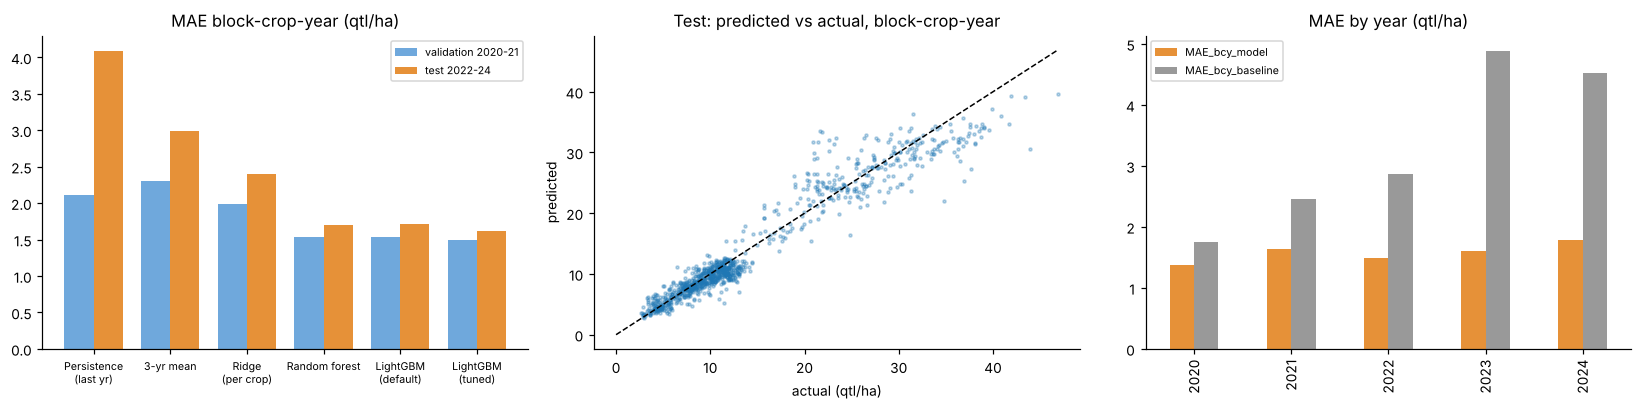

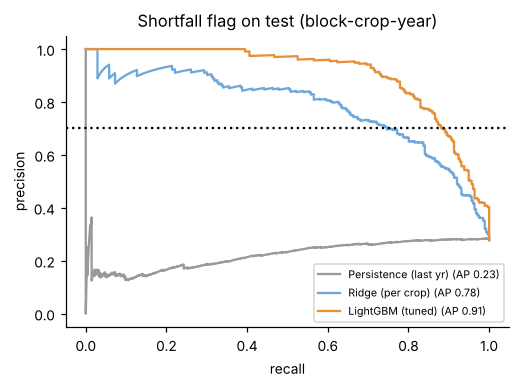

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(ORDER)); w = .38
ax[0].bar(x - w / 2, vdf.MAE_bcy.astype(float), w, label="validation 2020-21", color="#6fa8dc"); ax[0].bar(x + w / 2, tdf.MAE_bcy.astype(float), w, label="test 2022-24", color="#e69138")
ax[0].set_xticks(x); ax[0].set_xticklabels([o.replace(" (", "\n(") for o in ORDER], fontsize=7); ax[0].set_title("MAE block-crop-year (qtl/ha)"); ax[0].legend(fontsize=7)
bb = test_b[FIN]; ax[1].scatter(bb.y, bb.p, s=4, alpha=.3); lim = [0, bb[["y", "p"]].max().max()]; ax[1].plot(lim, lim, "k--", lw=1); ax[1].set_xlabel("actual (qtl/ha)"); ax[1].set_ylabel("predicted"); ax[1].set_title("Test: predicted vs actual, block-crop-year")
yrdf.set_index("year")[["MAE_bcy_model", "MAE_bcy_baseline"]].plot.bar(ax=ax[2], color=["#e69138", "#999"]); ax[2].set_title("MAE by year (qtl/ha)"); ax[2].set_xlabel(""); ax[2].legend(fontsize=7)
savefig("evaluation"); plt.show()
pr_fig, ax = plt.subplots(figsize=(4.8, 3.6))
for n, col in [("Persistence (last yr)", "#999"), ("Ridge (per crop)", "#6fa8dc"), (FIN, "#e69138")]:
    b = test_b[n]; pr_, rc_, _ = precision_recall_curve(b.actual, b.score); ax.plot(rc_, pr_, label=f"{n} (AP {test_res[n]['AP']:.2f})", color=col)
ax.axhline(PREC, ls=":", c="k"); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Shortfall flag on test (block-crop-year)"); ax.legend(fontsize=7)
savefig("pr_curve"); plt.show()

### Reading the results
__INTERP_RESULTS__

## 10. Explaining the model: SHAP and partial dependence
SHAP values are in *log-ratio* units, so 0.05 ≈ 5 % higher/lower than the village-crop's 3-year average yield. Computed on 4,000 random **test** rows.

       feature  mean_|SHAP|_%    group
irrigated_flag           7.27     plot
      rain_cum           6.46  weather
rain_ratio_req           6.04    ratio
        junsep           5.55  weather
      bc_roll3           4.27  rolling
      vc_roll3           3.92  rolling
    variety_te           3.20  encoded
 rain_anom_pct           2.96    ratio
       crop_id           2.53 category
 price_to_cost           2.15    ratio
   rain_octjan           1.70  weather
   junsep_lag1           1.69      lag

Share of total |SHAP| by feature group (%): {'weather': 26.3, 'ratio': 24.0, 'rolling': 14.6, 'plot': 11.4, 'lag': 8.4, 'encoded': 7.8, 'category': 4.9, 'soil': 2.5}
Spearman(feature value, SHAP) for top-8: {'irrigated_flag': 0.67, 'rain_cum': 0.62, 'rain_ratio_req': 0.53, 'junsep': 0.54, 'bc_roll3': -0.78, 'vc_roll3': -0.96, 'variety_te': 0.99, 'rain_anom_pct': 0.8}


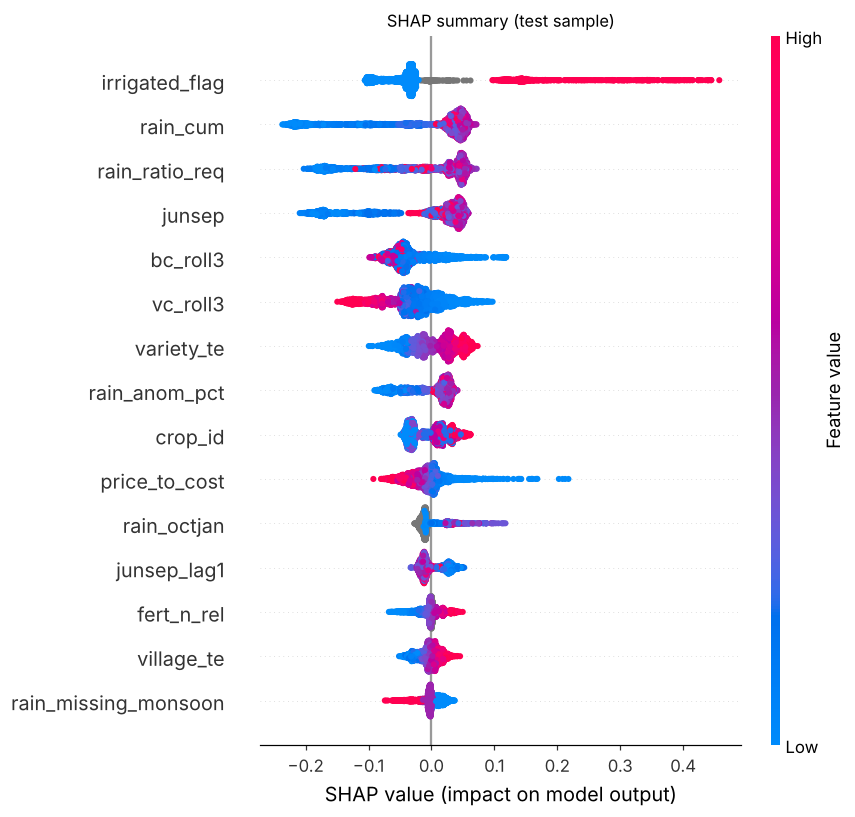

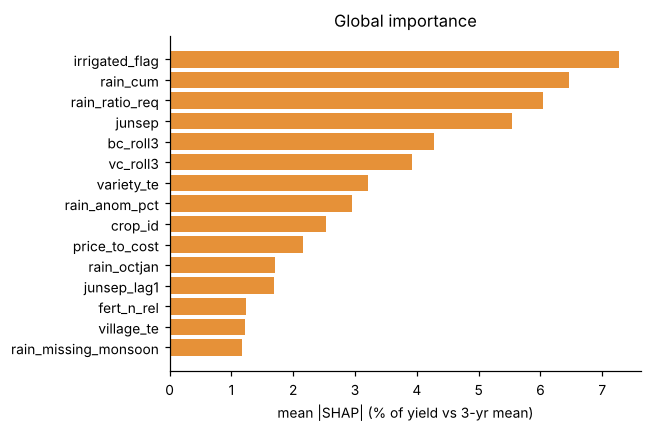

In [21]:
import shap
final = final_models[FIN]
samp = te.sample(4000 if not QUICK else 800, random_state=3)
expl = shap.TreeExplainer(final); sv = expl.shap_values(samp[FEAT])
imp = pd.Series(np.abs(sv).mean(0), FEAT).sort_values(ascending=False)
grp_of = {f: g for g, fs in FEATS.items() for f in fs}
top = pd.DataFrame({"feature": imp.index[:12], "mean_|SHAP|_%": (100 * imp.values[:12]).round(2), "group": [grp_of[f] for f in imp.index[:12]]}); print(top.to_string(index=False))
gimp = pd.Series({g: imp[fs].sum() for g, fs in FEATS.items()}).sort_values(ascending=False); print("\nShare of total |SHAP| by feature group (%):", (100 * gimp / gimp.sum()).round(1).to_dict())
METRICS["shap_top"] = top.to_dict("records"); METRICS["shap_groups"] = {k: float(v) for k, v in (100 * gimp / gimp.sum()).items()}
# direction checks: sign of the relation between feature value and its SHAP value
rows = []
for f in imp.index[:8]:
    xv = samp[f].values.astype(float); m = ~np.isnan(xv)
    rows.append((f, round(float(pd.Series(xv[m]).corr(pd.Series(sv[m, FEAT.index(f)]), method="spearman")), 2)))
print("Spearman(feature value, SHAP) for top-8:", dict(rows)); METRICS["shap_direction"] = dict(rows)
plt.figure(); shap.summary_plot(sv, samp[FEAT], max_display=15, show=False); plt.title("SHAP summary (test sample)"); savefig("shap_beeswarm"); plt.show()
plt.figure(figsize=(6, 4)); top15 = imp.head(15)[::-1]; plt.barh(top15.index, 100 * top15.values, color="#e69138"); plt.xlabel("mean |SHAP| (% of yield vs 3-yr mean)"); plt.title("Global importance"); savefig("shap_bar"); plt.show()

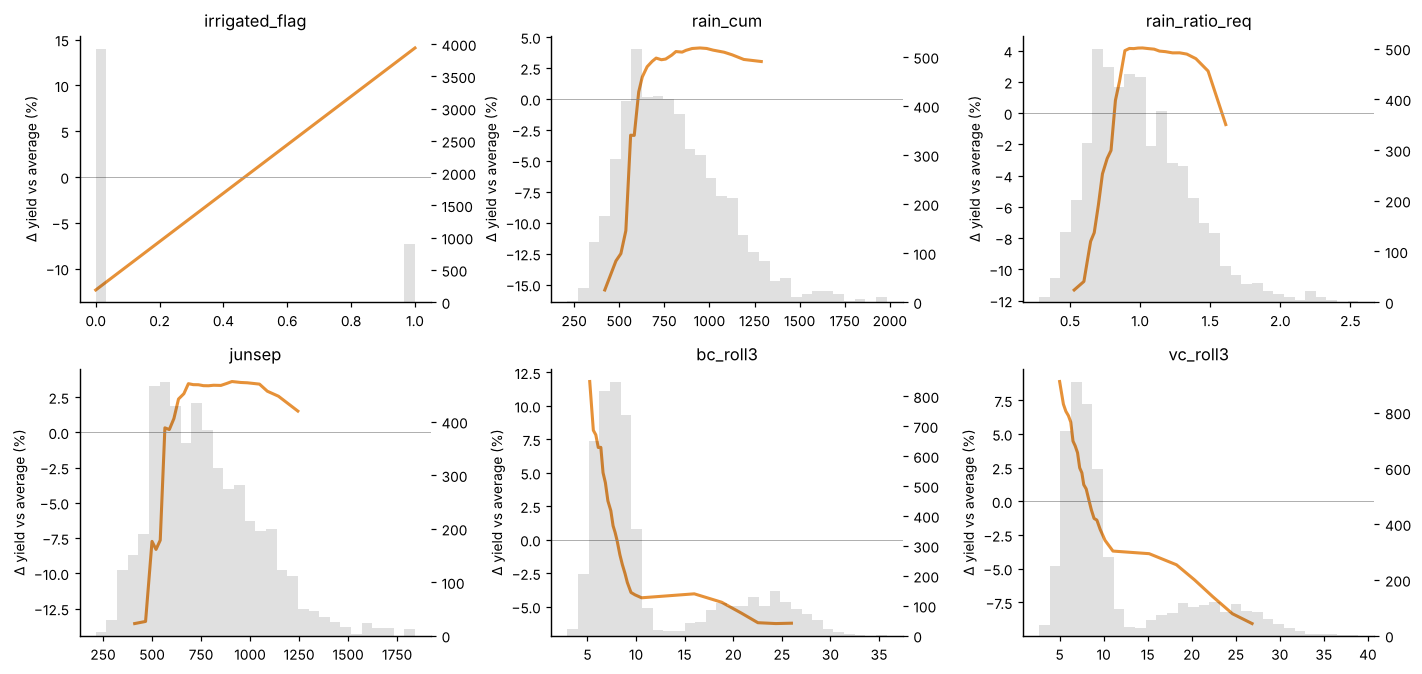

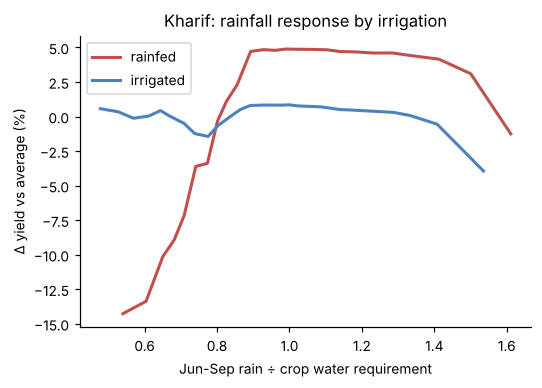

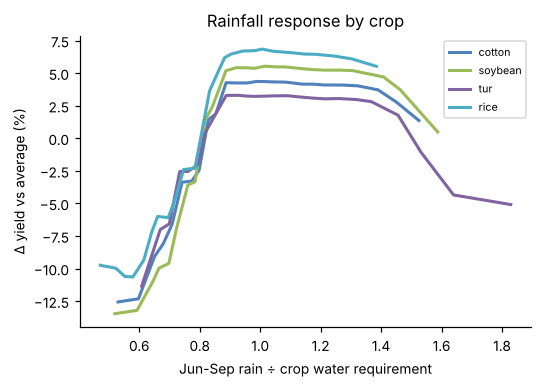

In [22]:
# Partial dependence (computed directly: average prediction as one feature is swept over its 5-95th percentile range)
pdp_base = tr.sample(5000 if not QUICK else 800, random_state=5)
def pdp(df, f, n=25, mask=None):
    d = df if mask is None else df[mask]
    grid = np.unique(np.nanpercentile(d[f], np.linspace(5, 95, n))); out = []
    for g in grid:
        X = d[FEAT].copy(); X[f] = g; out.append(final.predict(X).mean())
    out = np.array(out); return grid, 100 * (np.exp(out - np.mean(out)) - 1)
top6 = [f for f in imp.index if f not in ("crop_id", "district_id")][:6]
fig, ax = plt.subplots(2, 3, figsize=(13, 6.2))
for a, f in zip(ax.ravel(), top6):
    g, v = pdp(pdp_base, f); a.plot(g, v, color="#e69138", lw=2); a.set_title(f); a.set_ylabel("Δ yield vs average (%)"); a.axhline(0, c="#999", lw=.5)
    a.twinx().hist(pdp_base[f].dropna(), bins=30, alpha=.12, color="k")
savefig("pdp_top6"); plt.show()
# interaction story: rainfall sufficiency x irrigation (kharif only)
kb = pdp_base[(pdp_base.is_rabi == 0)]
fig, ax = plt.subplots(figsize=(5, 3.6))
for lab, mk, col in [("rainfed", kb.irrigated_flag == 0, "#c0504d"), ("irrigated", kb.irrigated_flag == 1, "#4f81bd")]:
    g, v = pdp(kb, "rain_ratio_req", mask=mk); ax.plot(g, v, label=lab, color=col, lw=2)
ax.set_xlabel("Jun-Sep rain ÷ crop water requirement"); ax.set_ylabel("Δ yield vs average (%)"); ax.set_title("Kharif: rainfall response by irrigation"); ax.legend(); savefig("pdp_rain_irrigation"); plt.show()
fig, ax = plt.subplots(figsize=(5, 3.6)); cols = {"cotton": "#4f81bd", "soybean": "#9bbb59", "tur": "#8064a2", "rice": "#4bacc6"}
for c, col in cols.items():
    g, v = pdp(pdp_base[pdp_base.crop == c], "rain_ratio_req"); ax.plot(g, v, label=c, color=col, lw=2)
ax.set_xlabel("Jun-Sep rain ÷ crop water requirement"); ax.set_ylabel("Δ yield vs average (%)"); ax.set_title("Rainfall response by crop"); ax.legend(fontsize=7); savefig("pdp_rain_crop"); plt.show()

### Do the top drivers make business sense?
__INTERP_SHAP__

## 11. One wrong prediction, in detail
We pick the village-crop-season in the **test period** with the largest absolute error among those with ≥ 5 crop-cutting plots (so the "actual" is trustworthy), then look at (i) what the model saw, (ii) how the
SHAP contributions add up to the forecast, (iii) whether neighbours were wrong in the same direction (a sign of a *common shock* the inputs could not contain).

village_id    YVT-B03-V11
crop                wheat
year                 2024
y               37.429167
p               20.072232
base              10.2525
n                       6
district         Yavatmal
block             YVT-B03
ref             23.979722
err            -17.356935

Prediction 20.1 qtl/ha vs actual 37.4 (error -17.4, -46%). Persistence baseline said 10.3; 3-yr mean 24.0.
This village-crop history (qtl/ha): {2015: 20.0, 2016: 35.4, 2017: 18.3, 2018: 21.2, 2019: 28.4, 2020: 32.2, 2021: 33.9, 2022: 27.8, 2023: 10.3, 2024: 37.4}

Same district-crop-year (Yavatmal, wheat, 2024): 37 villages, median error -12%, share over-predicted by >15%: 0%
Other districts, same crop-year: median error -6%


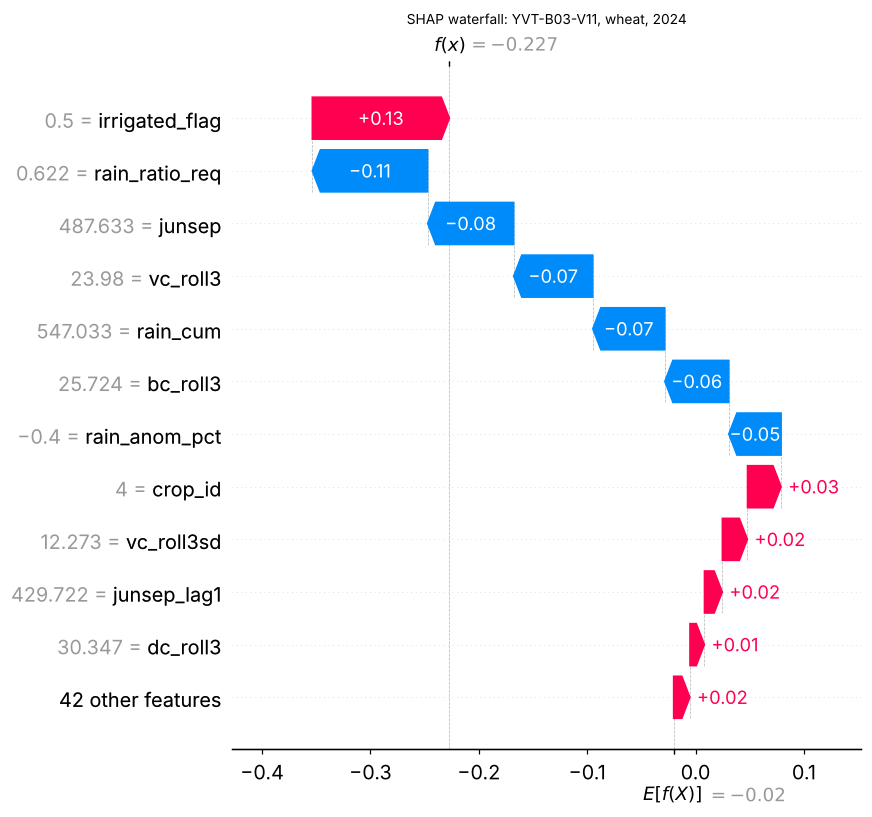


Key inputs the model saw (mean over plots):
 junsep                  487.63
rain_cum                547.03
rain_ratio_req            0.62
rain_anom_pct            -0.40
rain_missing_monsoon      1.00
irrigated_flag            0.50
sow_delay                -0.40
vc_lag1                  10.25
vc_roll3                 23.98

Top SHAP contributions (log-ratio): {'irrigated_flag': 0.127, 'rain_ratio_req': -0.106, 'junsep': -0.079, 'vc_roll3': -0.073, 'rain_cum': -0.066, 'bc_roll3': -0.059} | base value -0.02 | model log-ratio -0.227 | actual log-ratio 0.445

Test district-crop-years biased by >12%:
   district    crop  year  rel_bias_pct     n
  Yavatmal    gram  2024         -21.6 277.0
  Yavatmal  cotton  2024         -19.2 687.0
  Amravati    gram  2024         -18.9 427.0
    Wardha soybean  2023         -18.9 574.0
  Amravati  cotton  2022         -18.5 625.0
    Wardha  cotton  2022         -17.6 668.0
  Bhandara  cotton  2024         -14.9  15.0
    Wardha  cotton  2023         -14

In [23]:
te_ = te.assign(p=pt, base=pb)
v = te_.groupby(["village_id", "crop", "year"]).agg(y=("y", "mean"), p=("p", "mean"), base=("base", "mean"), n=("y", "size"), district=("district", "first"), block=("block", "first"), ref=("ref", "mean")).reset_index()
v["err"] = v.p - v.y; v = v[v.n >= 5]
worst = v.loc[v.err.abs().idxmax()]; print(worst.to_string())
sel = te_[(te_.village_id == worst.village_id) & (te_.crop == worst.crop) & (te_.year == worst.year)]
print(f"\nPrediction {worst.p:.1f} qtl/ha vs actual {worst.y:.1f} (error {worst.err:+.1f}, {100 * worst.err / worst.y:+.0f}%). Persistence baseline said {worst.base:.1f}; 3-yr mean {worst.ref:.1f}.")
hist = vcy[(vcy.village_id == worst.village_id) & (vcy.crop == worst.crop)].set_index("year").y_vc.round(1); print("This village-crop history (qtl/ha):", hist.loc[2015:].to_dict())
peer = te_[(te_.district == worst.district) & (te_.crop == worst.crop) & (te_.year == worst.year)]
pv = peer.groupby("village_id").agg(y=("y", "mean"), p=("p", "mean")); pv["err_pct"] = 100 * (pv.p / pv.y - 1)
print(f"\nSame district-crop-year ({worst.district}, {worst.crop}, {int(worst.year)}): {len(pv)} villages, median error {pv.err_pct.median():+.0f}%, share over-predicted by >15%: {100 * (pv.err_pct > 15).mean():.0f}%")
other = te_[(te_.district != worst.district) & (te_.crop == worst.crop) & (te_.year == worst.year)]; ov = other.groupby("village_id").agg(y=("y", "mean"), p=("p", "mean"))
print(f"Other districts, same crop-year: median error {100 * (ov.p / ov.y - 1).median():+.0f}%")
Xr = sel[FEAT]; shv = expl.shap_values(Xr); base_val = float(np.ravel(expl.expected_value)[0])
mean_sv = shv.mean(0); mean_x = Xr.mean(numeric_only=True)
ex = shap.Explanation(values=mean_sv, base_values=base_val, data=Xr.mean().values, feature_names=FEAT)
plt.figure(); shap.plots.waterfall(ex, max_display=12, show=False); plt.title(f"SHAP waterfall: {worst.village_id}, {worst.crop}, {int(worst.year)}", fontsize=9); savefig("wrong_prediction_waterfall"); plt.show()
rain_row = sel[["junsep", "rain_cum", "rain_ratio_req", "rain_anom_pct", "rain_missing_monsoon", "irrigated_flag", "sow_delay", "vc_lag1", "vc_roll3"]].mean().round(2); print("\nKey inputs the model saw (mean over plots):\n", rain_row.to_string())
cs = pd.Series(mean_sv, FEAT).sort_values(key=abs, ascending=False).head(6); print("\nTop SHAP contributions (log-ratio):", cs.round(3).to_dict(), "| base value", round(base_val, 3), "| model log-ratio", round(float(mean_sv.sum() + base_val), 3), "| actual log-ratio", round(float(np.log(worst.y / worst.ref)), 3))
METRICS["wrong"] = dict(village=worst.village_id, crop=worst.crop, year=int(worst.year), district=worst.district, pred=float(worst.p), actual=float(worst.y), base=float(worst.base), ref=float(worst.ref), n=int(worst.n),
                        peer_median_err_pct=float(pv.err_pct.median()), peer_share_over15=float(100 * (pv.err_pct > 15).mean()), other_dist_err_pct=float(100 * (ov.p / ov.y - 1).median()),
                        shap_top={k: float(x) for k, x in cs.items()}, inputs={k: float(x) for k, x in rain_row.items()}, hist={int(k): float(x) for k, x in hist.loc[2018:].items()})
# how typical is a miss of this kind? error by (district, crop, year) cell on test, to see which cells are systematically wrong
cell = te_.groupby(["district", "crop", "year"]).apply(lambda d: pd.Series(dict(rel_bias_pct=100 * (d.p.mean() / d.y.mean() - 1), n=len(d)))).reset_index()
big = cell[cell.rel_bias_pct.abs() > 12].sort_values("rel_bias_pct"); print("\nTest district-crop-years biased by >12%:\n", big.round(1).to_string(index=False)); METRICS["big_bias_cells"] = big.round(1).to_dict("records")

### Anatomy of the miss
__INTERP_WRONG__

## 12. Fairness and stability (stretch)
"Groups" here are **regions** (district), **crops**, **irrigation status**, **farm size** (a proxy for customer segment) and **data completeness**. Per group, on the test period:
relative MAE (MAE ÷ mean yield) and *bias* (mean prediction ÷ mean actual − 1). Rule of thumb used here: |bias| > 5 % or relative-MAE more than 1.5× the best group → flag.

In [24]:
te_ = te.assign(p=pt)
te_["farm_size"] = pd.cut(te_.plot_area_ha, [0, 1, 2, 100], labels=["<1 ha (marginal)", "1-2 ha (small)", ">2 ha (medium/large)"]).astype(str)
te_["irrig"] = te_.irrigated.fillna("unknown"); te_["data_complete"] = np.where((te_.fert_missing == 1) | (te_.rain_missing_monsoon > 0), "≥1 input imputed/missing", "all inputs observed")
def grp_table(df, col):
    g = df.groupby(col).apply(lambda d: pd.Series(dict(n=len(d), mean_yield=d.y.mean(), MAE=(d.p - d.y).abs().mean(), rel_MAE_pct=100 * (d.p - d.y).abs().mean() / d.y.mean(), bias_pct=100 * (d.p.mean() / d.y.mean() - 1)))).round(2)
    g.index = [f"{col}: {i}" for i in g.index]; return g
fair = pd.concat([grp_table(te_, c) for c in ["district", "crop", "irrig", "farm_size", "data_complete"]]); print(fair.to_string())
flag = fair[(fair.bias_pct.abs() > 5) | (fair.rel_MAE_pct > 1.5 * fair.rel_MAE_pct.min())]; print("\nFlagged groups:\n", flag.to_string() if len(flag) else "none")
METRICS["fair_before"] = fair.reset_index().rename(columns={"index": "group"}).to_dict("records")

                                               n  mean_yield   MAE  rel_MAE_pct  bias_pct
district: Amravati                        7645.0       11.70  2.04        17.48     -4.89
district: Bhandara                        6689.0       18.67  2.55        13.66      1.25
district: Chandrapur                      6758.0       13.31  1.84        13.84     -1.39
district: Nagpur                          7825.0       14.42  2.11        14.64     -4.51
district: Wardha                          7662.0       12.65  2.16        17.06     -2.10
district: Yavatmal                        7315.0        9.88  1.73        17.52     -4.03
crop: cotton                              9913.0        9.05  1.44        15.90     -9.05
crop: gram                                5546.0       10.16  1.70        16.77     -0.87
crop: rice                                5022.0       21.80  3.11        14.26      0.28
crop: soybean                             8710.0        9.04  1.43        15.80     -4.18
crop: tur 

Within-validation check (fit 2020 → apply 2021): {'mean_abs_cell_bias_before': np.float64(8.327), 'after': np.float64(7.855), 'MAE_before': 1.63, 'MAE_after': 1.59}
Adopt recalibration? True
              MAE_bcy  MAE_row  mean_|cell bias| %
uncalibrated    1.623    2.070               4.206
recalibrated    1.616    2.063               3.722


                                         rel_MAE_pct  bias_pct  rel_MAE_pct_recal  bias_pct_recal
district: Amravati                             17.48     -4.89              17.05           -3.05
district: Bhandara                             13.66      1.25              14.29            3.31
district: Chandrapur                           13.84     -1.39              13.82           -0.75
district: Nagpur                               14.64     -4.51              14.41           -0.97
district: Wardha                               17.06     -2.10              16.62            0.06
district: Yavatmal                             17.52     -4.03              17.50           -1.52
crop: cotton                                   15.90     -9.05              14.72           -3.29
crop: gram                                     16.77     -0.87              16.95           -0.83
crop: rice                                     14.26      0.28              14.20           -0.41
crop: soybean       

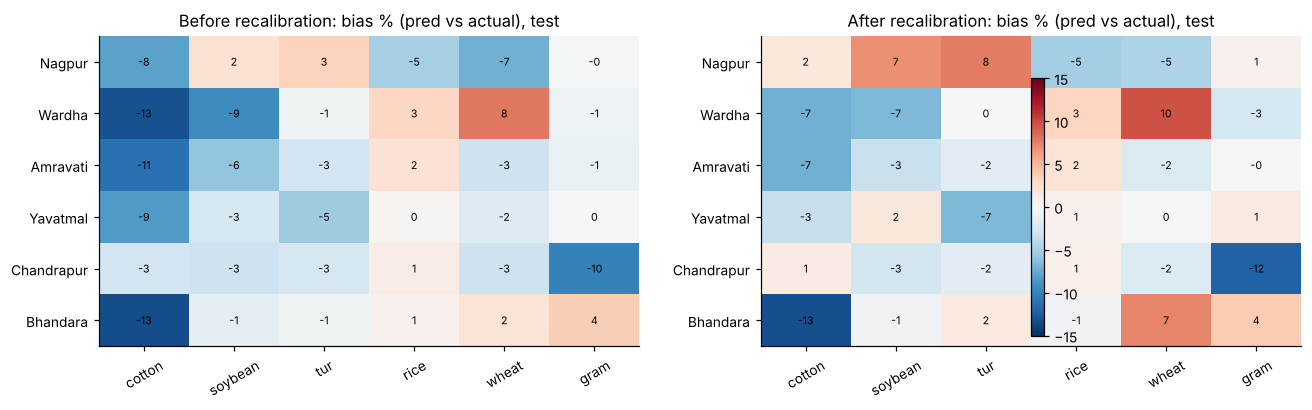

In [25]:
# Recalibration: multiplicative correction per (district, crop), estimated on VALIDATION, shrunk toward 0 (k=1500 plots).
def fit_calib(df, p, k=1500):
    d = df.assign(p=p).groupby(["district", "crop"]).apply(lambda g: pd.Series(dict(b=g.p.mean() / g.y.mean() - 1, n=len(g)))).reset_index()
    d["factor"] = 1 / (1 + d.b * d.n / (d.n + k)); return d.set_index(["district", "crop"]).factor
def apply_calib(df, p, fac):
    f = pd.MultiIndex.from_arrays([df.district, df.crop]).map(fac.to_dict().get); return p * np.array([x if x is not None else 1.0 for x in f], dtype=float)
pv_ = predict_final(FIN, va)
# decision made INSIDE validation: fit on 2020, check on 2021
va20, va21 = va[va.year == 2020], va[va.year == 2021]; fac20 = fit_calib(va20, pv_[(va.year == 2020).values])
p21 = pv_[(va.year == 2021).values]; p21c = apply_calib(va21, p21, fac20)
def worst_bias(df, p): return df.assign(p=p).groupby(["district", "crop"]).apply(lambda g: abs(g.p.mean() / g.y.mean() - 1)).mean()
chk = dict(mean_abs_cell_bias_before=100 * worst_bias(va21, p21), after=100 * worst_bias(va21, p21c), MAE_before=basic(va21, p21)["MAE_bcy"], MAE_after=basic(va21, p21c)["MAE_bcy"])
print("Within-validation check (fit 2020 → apply 2021):", {k: round(v, 3) for k, v in chk.items()})
ADOPT = (chk["mean_abs_cell_bias_before"] - chk["after"] > 0.2) and (chk["MAE_after"] <= chk["MAE_before"] * 1.01)
print("Adopt recalibration?", ADOPT)
fac_final = fit_calib(va, pv_); pt_cal = apply_calib(te, pt, fac_final) if ADOPT else pt
rep = pd.DataFrame({"MAE_bcy": [basic(te, pt)["MAE_bcy"], basic(te, pt_cal)["MAE_bcy"]], "MAE_row": [basic(te, pt)["MAE_row"], basic(te, pt_cal)["MAE_row"]],
                    "mean_|cell bias| %": [100 * worst_bias(te, pt), 100 * worst_bias(te, pt_cal)]}, index=["uncalibrated", "recalibrated"]).round(3); print(rep)
METRICS["recal"] = dict(adopt=bool(ADOPT), within_val=chk, test=rep.reset_index().to_dict("records"))
te_c = te.assign(p=pt_cal); fair2 = pd.concat([grp_table(te_c.assign(farm_size=te_.farm_size, irrig=te_.irrig, data_complete=te_.data_complete), c) for c in ["district", "crop", "irrig", "farm_size", "data_complete"]])
cmp_ = fair[["rel_MAE_pct", "bias_pct"]].join(fair2[["rel_MAE_pct", "bias_pct"]], rsuffix="_recal"); print(cmp_.to_string()); METRICS["fair_after"] = fair2.reset_index().rename(columns={"index": "group"}).to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (title, pp) in zip(ax, [("Before recalibration", pt), ("After recalibration" if ADOPT else "Recalibration not adopted", pt_cal)]):
    hmx = te.assign(p=pp).groupby(["district", "crop"]).apply(lambda g: 100 * (g.p.mean() / g.y.mean() - 1)).unstack()[CROPS].loc[DIST]
    im = a.imshow(hmx.values, cmap="RdBu_r", vmin=-15, vmax=15, aspect="auto"); a.set_xticks(range(6)); a.set_xticklabels(CROPS, rotation=30); a.set_yticks(range(6)); a.set_yticklabels(DIST); a.set_title(title + ": bias % (pred vs actual), test")
    for i in range(6):
        for j in range(6): a.text(j, i, f"{hmx.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=.8); savefig("fairness_bias_heatmap"); plt.show()

In [26]:
# Stability: (1) input-noise sensitivity of rainfall, (2) simulated extra gauge failures (rain replaced by district-year mean of OTHER blocks' rain, i.e. what the imputer would do)
def perturb_rain(df, sigma, seed=0):
    r = np.random.RandomState(seed); s = np.exp(r.normal(0, sigma, len(df))); d = df.copy()
    for c in ["junsep", "rain_cum", "rain_ja", "r_jun", "r_sep", "rain_octjan", "rain_ratio_req", "rain_intensity"]: d[c] = d[c] * s
    d["rain_anom_pct"] = (1 + d.rain_anom_pct) * s - 1; return d
rows = []
for sg in (0.05, 0.15):
    dp = perturb_rain(te, sg); pp = rel_pred(dp, final.predict(dp[FEAT]))
    rows.append(dict(rain_noise_sd=f"{int(sg * 100)}%", mean_abs_change_in_forecast_pct=100 * np.mean(np.abs(pp / pt - 1)), MAE_bcy=basic(te, pp)["MAE_bcy"], MAE_bcy_unperturbed=basic(te, pt)["MAE_bcy"]))
stab = pd.DataFrame(rows).round(3); print(stab.to_string(index=False)); METRICS["stability_noise"] = stab.to_dict("records")
wd = te.copy(); blk_dist = wd.groupby(["district", "year"]).junsep.transform("mean")
# gauge-failure stress: replace each affected block's rainfall inputs by its district-year mean (30% of blocks)
rr = np.random.RandomState(1); fail_blocks = set(rr.choice(wd.block.unique(), 18, replace=False)); m = wd.block.isin(fail_blocks)
ratio_ = (blk_dist / wd.junsep)[m]
for c in ["junsep", "rain_cum", "rain_ja", "r_jun", "r_sep", "rain_octjan", "rain_ratio_req", "rain_intensity"]: wd.loc[m, c] = wd.loc[m, c] * ratio_
pg = rel_pred(wd, final.predict(wd[FEAT])); print(f"Gauge-failure stress (30% of blocks fall back to district-year mean rain): MAE_bcy {basic(te, pt)['MAE_bcy']:.3f} → {basic(te, pg)['MAE_bcy']:.3f}")
METRICS["stability_gauge"] = dict(before=float(basic(te, pt)["MAE_bcy"]), after=float(basic(te, pg)["MAE_bcy"]))

rain_noise_sd  mean_abs_change_in_forecast_pct  MAE_bcy  MAE_bcy_unperturbed
           5%                            2.522    1.618                1.623
          15%                            7.015    1.680                1.623


Gauge-failure stress (30% of blocks fall back to district-year mean rain): MAE_bcy 1.623 → 1.744


### Fairness and stability: what we found and did
__INTERP_FAIR__

## 13. From forecasts to procurement actions
District-crop forecasts (average of block/plot forecasts) are combined with sown area (reported at sowing, so known at forecast time) to get **expected harvest volume**, and with the trailing 3-year yield to get a **shortfall risk**
(forecast ≥ 5 % below trailing mean = *at risk*). Because only data to 2024 exist, this is a **retro-forecast of 2024** (the last test season), scored against what actually happened.

{'model_tonnage_err_%': 7.7, 'baseline_tonnage_err_%': 23.8}

District-crop-year shortfall flags, test period (≥5% below trailing mean):
                       flagged  actual_at_risk  hits  precision  recall
model                    45.0            43.0  38.0       0.84    0.88
persistence baseline     48.0            43.0  10.0       0.21    0.23

Retro-forecast 2024: 36 district-crop pairs, median volume cut-off 26.3 kt
  district    crop  exp_kt  chg_pred  chg_act                        tier verdict_in_hindsight
  Bhandara    rice   105.6       8.9     -1.1            A  Lock in early         flag correct
    Nagpur   wheat    92.1       5.7     12.3            A  Lock in early         flag correct
    Nagpur  cotton    88.8      13.6      9.5            A  Lock in early         flag correct
Chandrapur    rice    83.0      12.9      2.0            A  Lock in early         flag correct
  Amravati soybean    74.9       8.5     18.4            A  Lock in early         flag correct
  A

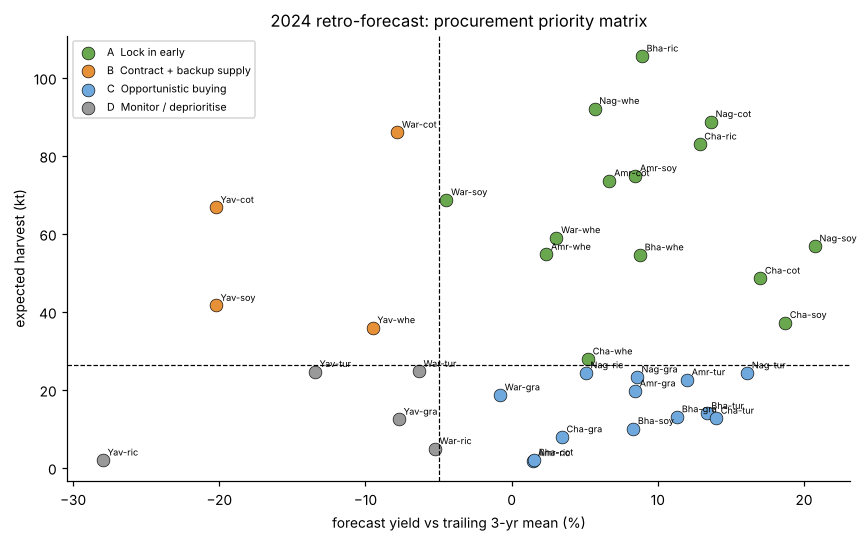

In [27]:
FC = pt_cal
dc = te.assign(p=FC, base=pb).groupby(["district", "crop", "year"]).agg(y=("y", "mean"), p=("p", "mean"), base=("base", "mean"), trail=("dc_roll3", "first"), area=("sown_area_ha", "first"), pm=("price_pre_mom", "mean")).reset_index()
dc["chg_pred"] = 100 * (dc.p / dc.trail - 1); dc["chg_act"] = 100 * (dc.y / dc.trail - 1); dc["chg_base"] = 100 * (dc.base / dc.trail - 1)
dc["exp_kt"] = dc.p * dc.area / 10000; dc["act_kt"] = dc.y * dc.area / 10000; dc["base_kt"] = dc.base * dc.area / 10000   # qtl→tonnes /10; /1000 → kt
tonn = pd.Series({"model_tonnage_err_%": 100 * (dc.exp_kt - dc.act_kt).abs().sum() / dc.act_kt.sum(), "baseline_tonnage_err_%": 100 * (dc.base_kt - dc.act_kt).abs().sum() / dc.act_kt.sum()}).round(1); print(tonn.to_dict())
RISK = -5.0; dc["risk_act"] = dc.chg_act <= RISK; dc["risk_pred"] = dc.chg_pred <= RISK; dc["risk_base"] = dc.chg_base <= RISK
def cm(a, b): tp = int((a & b).sum()); return dict(flagged=int(b.sum()), actual_at_risk=int(a.sum()), hits=tp, precision=round(tp / max(1, b.sum()), 2), recall=round(tp / max(1, a.sum()), 2))
cmp_risk = pd.DataFrame({"model": cm(dc.risk_act, dc.risk_pred), "persistence baseline": cm(dc.risk_act, dc.risk_base)}).T; print("\nDistrict-crop-year shortfall flags, test period (≥5% below trailing mean):\n", cmp_risk.to_string())
METRICS["dc_tonnage"] = tonn.to_dict(); METRICS["dc_risk"] = cmp_risk.reset_index().to_dict("records")
last = dc[dc.year == 2024].copy(); med = last.exp_kt.median(); last["high_vol"] = last.exp_kt >= med; last["at_risk"] = last.chg_pred <= RISK
def tier(r):
    if r.high_vol and not r.at_risk: return "A  Lock in early"
    if r.high_vol and r.at_risk: return "B  Contract + backup supply"
    if not r.high_vol and not r.at_risk: return "C  Opportunistic buying"
    return "D  Monitor / deprioritise"
last["tier"] = last.apply(tier, axis=1)
act = {"A  Lock in early": "Sign forward contracts / secure storage and logistics now: large volume, reliable crop.",
       "B  Contract + backup supply": "Contract the expected volume but cap exposure; pre-arrange second-district sourcing and price protection: large volume with a forecast shortfall.",
       "C  Opportunistic buying": "Buy spot at harvest; no early commitment needed: small volume, no shortfall signal.",
       "D  Monitor / deprioritise": "Do not commit capital early; re-forecast at the next cutoff: small volume and a shortfall signal."}
last["action"] = last.tier.map(act); last["verdict_in_hindsight"] = np.where(last.at_risk == (last.chg_act <= RISK), "flag correct", np.where(last.at_risk, "false alarm", "missed shortfall"))
show = last.sort_values(["tier", "exp_kt"], ascending=[True, False])[["district", "crop", "exp_kt", "chg_pred", "chg_act", "tier", "verdict_in_hindsight"]].round(1)
print(f"\nRetro-forecast 2024: {len(last)} district-crop pairs, median volume cut-off {med:.1f} kt"); print(show.to_string(index=False))
print("\nTier counts:", last.tier.value_counts().to_dict(), "| flag hindsight:", last.verdict_in_hindsight.value_counts().to_dict())
last.drop(columns=["high_vol"]).round(2).to_csv(f"{OUTD}/procurement_priority_2024.csv", index=False)
METRICS["tiers"] = last.tier.value_counts().to_dict(); METRICS["tier_hindsight"] = last.verdict_in_hindsight.value_counts().to_dict(); METRICS["proc_median_kt"] = float(med)
METRICS["proc_table"] = show.to_dict("records")
fig, ax = plt.subplots(figsize=(8, 5)); colmap = {"A  Lock in early": "#6aa84f", "B  Contract + backup supply": "#e69138", "C  Opportunistic buying": "#6fa8dc", "D  Monitor / deprioritise": "#999999"}
for t_, g in last.groupby("tier"): ax.scatter(g.chg_pred, g.exp_kt, s=70, c=colmap[t_], label=t_, edgecolor="k", lw=.4)
for _, r in last.iterrows(): ax.annotate(f"{r.district[:3]}-{r.crop[:3]}", (r.chg_pred, r.exp_kt), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.axvline(RISK, ls="--", c="k", lw=.8); ax.axhline(med, ls="--", c="k", lw=.8); ax.set_xlabel("forecast yield vs trailing 3-yr mean (%)"); ax.set_ylabel("expected harvest (kt)"); ax.set_title("2024 retro-forecast: procurement priority matrix"); ax.legend(fontsize=7)
savefig("procurement_matrix"); plt.show()

### Recommended actions
__INTERP_ACTIONS__

## 14. Save artefacts

In [28]:
bundle = dict(model=final, features=FEAT, categorical=["crop_id", "district_id"], target="log(yield / vc_roll3)", ref_column="vc_roll3",
              crop_id={c: i for i, c in enumerate(CROPS)}, district_id={d: i for i, d in enumerate(DIST)},
              recalibration=(fac_final.reset_index().to_dict("records") if ADOPT else None), shortfall_threshold=thr[FIN], shortfall_rule=f"flag block-crop if 1 - forecast/trailing3 >= threshold (shortfall = actual < {SHORT} x trailing 3-yr mean)",
              train_years=TRAIN_Y, val_years=VAL_Y, test_years=TEST_Y, params={**LGB_DEFAULT, **FINAL_CFG}, metrics=dict(criteria=METRICS["criteria"]),
              note="Trained on SYNTHETIC data. Not for operational use without retraining on real records.")
joblib.dump(bundle, f"{OUTD}/yield_model.joblib", compress=3)
te.assign(pred=pt_cal, baseline=pb)[["record_id", "district", "block", "village_id", "crop", "year", "y", "pred", "baseline"]].to_csv(f"{OUTD}/test_predictions.csv", index=False)
top.to_csv(f"{OUTD}/shap_top_features.csv", index=False); tune.to_csv(f"{OUTD}/tuning_results.csv", index=False); cv.to_csv(f"{OUTD}/cv_results.csv", index=False); fair.to_csv(f"{OUTD}/fairness_before.csv"); fair2.to_csv(f"{OUTD}/fairness_after.csv")
METRICS["feature_groups"] = FEATS; METRICS["final_params"] = {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v)) for k, v in {**LGB_DEFAULT, **FINAL_CFG}.items()}
json.dump(METRICS, open(f"{OUTD}/metrics.json", "w"), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
chk_b = joblib.load(f"{OUTD}/yield_model.joblib"); re_pred = rel_pred(te.head(2000), chk_b["model"].predict(te.head(2000)[chk_b["features"]]))
print("Reload check: max |difference| vs in-memory predictions =", float(np.abs(re_pred - predict_final(FIN, te.head(2000))).max()))
print("Saved:", sorted(os.listdir(OUTD)))

Reload check: max |difference| vs in-memory predictions = 0.0
Saved: ['cv_results.csv', 'fairness_after.csv', 'fairness_before.csv', 'metrics.json', 'procurement_priority_2024.csv', 'shap_top_features.csv', 'test_predictions.csv', 'tuning_results.csv', 'yield_model.joblib']
